In [ ]:
!rm -rf /content/drive

^C


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

print(os.listdir('/content/drive/MyDrive'))


Mounted at /content/drive
['Getting started.pdf', '2020-05-11 10-01-02.mkv', 'Classroom', '2020-05-11 10-59-53.mkv', '27-05-2020 tamil (1).mkv', '27-05-2020 biology.mkv', '27-05-2020 maths (2).mkv', '27-05-2020 tamil.mkv', 'Test 2 (10 Jun 2020 3:13:35 pm).jpeg', 'Test 2 (10 Jun 2020 3:15:07 pm).jpeg', 'Test 2 (10 Jun 2020 3:16:33 pm).jpeg', 'Exercise 3.15  question number 1) ii and iii (18 Jun 2020 5:27:11 pm).jpeg', '24 Jun 2020 5:45:00 pm.jpeg', '24 Jun 2020 5:46:48 pm.jpeg', '20200625_154537.jpg', 'Test: 3 (29 Jun 2020 3:34:59 pm).jpeg', 'Test: 3 (29 Jun 2020 3:36:00 pm).jpeg', 'Test: 3 (29 Jun 2020 3:35:51 pm).jpeg', 'Test: 3 (29 Jun 2020 3:35:37 pm).jpeg', '20200629_153626.jpg', 'Bff-3.jpeg', 'Scan 18 Jul 2020 (2).pdf', 'Exercise 3.8 1) iv (21 Jul 2020 5:35:04 pm).jpeg', 'New doc 09-Aug-2020 9.45 PM.pdf', 'New doc 30-Sep-2020 7.13 PM.pdf', 'Tamil Ter End Exam II.pdf', 'VID20210103175638.mp4', '20190317192852.mpg', 'Edited - Computer WT-4.pdf', '28.03.23.mp4', '25.04.23.flv', '24.0

In [ ]:

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'MILK10k_Prepared' in dirs:
        print("Dataset found:", os.path.join(root, 'MILK10k_Prepared'))


**DATA PROCESSING**

In [ ]:
# ============================================================
# MILK10k DATA PREPARATION
# MELANOMA ViT PROJECT
#
# Purpose:
#   Prepare 2 images per lesion for Vision Transformer training
#
# Important:
#   - Lesion-level splitting
#   - Exactly 2 images per lesion
#   - Both images receive the same lesion label
#   - No data augmentation
#   - No hair removal
#   - No automatic lesion segmentation/cropping
#   - Aspect ratio preserved
#   - Images resized to 224 x 224
# ============================================================

import os
import cv2
import random
import shutil
import warnings
import numpy as np
import pandas as pd

from PIL import Image
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

# Original image folder
MILK_ROOT = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k",
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

# Ground truth
GROUND_TRUTH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k",
    "MILK10k_Training_GroundTruth.csv"
)

# Output folder
OUTPUT_ROOT = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

# Processed image folders
TRAIN_DIR = os.path.join(OUTPUT_ROOT, "train")
VAL_DIR   = os.path.join(OUTPUT_ROOT, "validation")
TEST_DIR  = os.path.join(OUTPUT_ROOT, "test")

# Reports
REPORT_DIR = os.path.join(OUTPUT_ROOT, "reports")

# Image size for ViT
IMAGE_SIZE = 224


# ============================================================
# 2. PRINT PATHS
# ============================================================

print("=" * 70)
print("MILK10k FINAL DATA PREPARATION")
print("MELANOMA ViT PROJECT")
print("=" * 70)

print("\nBASE PATH:")
print(BASE_PATH)

print("\nIMAGE ROOT:")
print(MILK_ROOT)

print("\nGROUND TRUTH:")
print(GROUND_TRUTH)

print("\nOUTPUT:")
print(OUTPUT_ROOT)


# ============================================================
# 3. CHECK PATHS
# ============================================================

print("\n" + "=" * 70)
print("CHECKING PATHS")
print("=" * 70)

print("\nImage root exists :", os.path.exists(MILK_ROOT))
print("Ground truth exists:", os.path.exists(GROUND_TRUTH))

if not os.path.exists(MILK_ROOT):
    raise FileNotFoundError(
        "\nImage folder not found:\n" + MILK_ROOT
    )

if not os.path.exists(GROUND_TRUTH):
    raise FileNotFoundError(
        "\nGround truth file not found:\n" + GROUND_TRUTH
    )

print("\nBoth paths found successfully.")


# ============================================================
# 4. CREATE OUTPUT DIRECTORIES
# ============================================================

os.makedirs(OUTPUT_ROOT, exist_ok=True)
os.makedirs(TRAIN_DIR, exist_ok=True)
os.makedirs(VAL_DIR, exist_ok=True)
os.makedirs(TEST_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)


# ============================================================
# 5. LOAD GROUND TRUTH
# ============================================================

print("\n" + "=" * 70)
print("LOADING GROUND TRUTH")
print("=" * 70)

df = pd.read_csv(GROUND_TRUTH)

print("\nGround truth shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ============================================================
# 6. CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "lesion_id",
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns in ground truth: "
        + str(missing_columns)
    )

print("\nAll required columns are present.")


# ============================================================
# 7. CLEAN LESION IDs
# ============================================================

df["lesion_id"] = (
    df["lesion_id"]
    .astype(str)
    .str.strip()
)

# Remove empty IDs
df = df[df["lesion_id"] != ""].copy()

# Remove duplicate lesion IDs
duplicate_count = df["lesion_id"].duplicated().sum()

print("\nDuplicate lesion IDs:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates(
        subset=["lesion_id"],
        keep="first"
    )


# ============================================================
# 8. CONVERT DIAGNOSIS COLUMNS TO NUMERIC
# ============================================================

diagnosis_columns = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

for col in diagnosis_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    ).fillna(0)

    df[col] = (df[col] > 0).astype(int)


# ============================================================
# 9. CHECK LABELS
# ============================================================

df["label_count"] = df[diagnosis_columns].sum(axis=1)

no_label = df["label_count"] == 0
multiple_labels = df["label_count"] > 1

print("\nNo-label records:", no_label.sum())
print("Multiple-label records:", multiple_labels.sum())

# Remove invalid records
df = df[
    (df["label_count"] == 1)
].copy()

df.drop(columns=["label_count"], inplace=True)


# ============================================================
# 10. CREATE BINARY MELANOMA LABEL
# ============================================================
#
# MEL = 1  -> Melanoma
# Others   -> Non-Melanoma = 0
#
# ============================================================

df["label"] = df["MEL"].astype(int)

df["class_name"] = df["label"].map({
    0: "Non-Melanoma",
    1: "Melanoma"
})


# ============================================================
# 11. LABEL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("LABEL SUMMARY")
print("=" * 70)

print(
    df["class_name"].value_counts()
)

print("\nMelanoma lesions:",
      int((df["label"] == 1).sum()))

print("Non-Melanoma lesions:",
      int((df["label"] == 0).sum()))


# ============================================================
# 12. FIND IMAGE FILES
# ============================================================

print("\n" + "=" * 70)
print("SCANNING IMAGE FOLDERS")
print("=" * 70)

valid_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


def find_images(folder):

    image_files = []

    if not os.path.isdir(folder):
        return image_files

    for root, dirs, files in os.walk(folder):

        for file in files:

            if file.lower().endswith(valid_extensions):

                image_files.append(
                    os.path.join(root, file)
                )

    return image_files


# ============================================================
# 13. VERIFY EACH LESION
# ============================================================

records = []

missing_lesions = []
wrong_image_count = []
more_than_two = []

for index, row in df.iterrows():

    lesion_id = row["lesion_id"]

    lesion_folder = os.path.join(
        MILK_ROOT,
        lesion_id
    )

    image_files = find_images(
        lesion_folder
    )

    # No images
    if len(image_files) == 0:

        missing_lesions.append(
            lesion_id
        )

        continue

    # Not exactly 2 images
    if len(image_files) != 2:

        wrong_image_count.append({
            "lesion_id": lesion_id,
            "image_count": len(image_files)
        })

        if len(image_files) > 2:
            more_than_two.append({
                "lesion_id": lesion_id,
                "image_count": len(image_files)
            })

        continue

    # Keep both images
    #
    # IMPORTANT:
    # We do NOT assume image 1 = clinical
    # and image 2 = dermoscopic.
    #
    for image_path in image_files:

        records.append({

            "lesion_id": lesion_id,

            "image_path": image_path,

            "label": int(row["label"]),

            "class_name": row["class_name"]

        })


# ============================================================
# 14. SAVE IMAGE COUNT REPORT
# ============================================================

image_count_report = pd.DataFrame(
    wrong_image_count
)

image_count_report.to_csv(
    os.path.join(
        REPORT_DIR,
        "wrong_image_count.csv"
    ),
    index=False
)

pd.DataFrame({
    "lesion_id": missing_lesions
}).to_csv(
    os.path.join(
        REPORT_DIR,
        "missing_lesions.csv"
    ),
    index=False
)

pd.DataFrame(
    more_than_two
).to_csv(
    os.path.join(
        REPORT_DIR,
        "more_than_two_images.csv"
    ),
    index=False
)


# ============================================================
# 15. IMAGE SCAN SUMMARY
# ============================================================

print("\nLesions in ground truth:",
      len(df))

print("Lesions with no images:",
      len(missing_lesions))

print("Lesions with image count != 2:",
      len(wrong_image_count))

print("Valid lesions with exactly 2 images:",
      len(records) // 2)


# ============================================================
# 16. CREATE LESION-LEVEL DATAFRAME
# ============================================================

if len(records) == 0:
    raise ValueError(
        "No valid lesions with exactly 2 images were found."
    )

image_df = pd.DataFrame(records)

lesion_df = (
    image_df[
        [
            "lesion_id",
            "label",
            "class_name"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("\nValid lesion count:",
      len(lesion_df))


# ============================================================
# 17. LESION-LEVEL TRAIN / VAL / TEST SPLIT
# ============================================================
#
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
#
# IMPORTANT:
# Split is performed using lesion_id.
#
# Therefore, both images from the same lesion
# always stay in the same split.
# ============================================================

train_lesions, temp_lesions = train_test_split(
    lesion_df,
    test_size=0.30,
    stratify=lesion_df["label"],
    random_state=SEED
)

val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["label"],
    random_state=SEED
)


# ============================================================
# 18. ADD SPLIT INFORMATION
# ============================================================

train_lesions = train_lesions.copy()
val_lesions = val_lesions.copy()
test_lesions = test_lesions.copy()

train_lesions["split"] = "train"
val_lesions["split"] = "validation"
test_lesions["split"] = "test"


# ============================================================
# 19. PRINT SPLIT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL SPLIT")
print("=" * 70)

print("\nTraining lesions:",
      len(train_lesions))

print("Validation lesions:",
      len(val_lesions))

print("Test lesions:",
      len(test_lesions))

print("\nTraining class distribution:")
print(train_lesions["class_name"].value_counts())

print("\nValidation class distribution:")
print(val_lesions["class_name"].value_counts())

print("\nTest class distribution:")
print(test_lesions["class_name"].value_counts())


# ============================================================
# 20. SAVE LESION-LEVEL CSV FILES
# ============================================================

train_lesions.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "train_lesions.csv"
    ),
    index=False
)

val_lesions.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "validation_lesions.csv"
    ),
    index=False
)

test_lesions.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "test_lesions.csv"
    ),
    index=False
)


# ============================================================
# 21. CREATE SPLIT LOOKUP
# ============================================================

split_lookup = {}

for lesion_id in train_lesions["lesion_id"]:
    split_lookup[lesion_id] = "train"

for lesion_id in val_lesions["lesion_id"]:
    split_lookup[lesion_id] = "validation"

for lesion_id in test_lesions["lesion_id"]:
    split_lookup[lesion_id] = "test"


image_df["split"] = image_df[
    "lesion_id"
].map(split_lookup)


# ============================================================
# 22. CHECK SPLIT ASSIGNMENT
# ============================================================

if image_df["split"].isna().any():

    raise ValueError(
        "Some images do not have a split assignment."
    )


# ============================================================
# 23. RESIZE FUNCTION
# ============================================================
#
# No crop
# No segmentation
# No hair removal
# No augmentation
#
# Aspect ratio is preserved.
# Reflection padding is used.
#
# ============================================================

def resize_preserve_aspect(
    image,
    target_size=224
):

    h, w = image.shape[:2]

    if h <= 0 or w <= 0:
        raise ValueError(
            "Invalid image dimensions."
        )

    scale = min(
        target_size / w,
        target_size / h
    )

    new_w = max(
        1,
        int(round(w * scale))
    )

    new_h = max(
        1,
        int(round(h * scale))
    )

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    pad_left = (
        target_size - new_w
    ) // 2

    pad_right = (
        target_size - new_w
    ) - pad_left

    pad_top = (
        target_size - new_h
    ) // 2

    pad_bottom = (
        target_size - new_h
    ) - pad_top

    padded = cv2.copyMakeBorder(
        resized,
        pad_top,
        pad_bottom,
        pad_left,
        pad_right,
        borderType=cv2.BORDER_REFLECT_101
    )

    return padded


# ============================================================
# 24. PROCESS ONE IMAGE
# ============================================================

def process_image(
    source_path,
    destination_path
):

    image = cv2.imread(
        source_path,
        cv2.IMREAD_COLOR
    )

    if image is None:

        raise ValueError(
            "Could not read image:\n"
            + source_path
        )

    # OpenCV BGR -> RGB
    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Resize only
    image = resize_preserve_aspect(
        image,
        IMAGE_SIZE
    )

    # RGB -> BGR for cv2.imwrite
    image = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2BGR
    )

    success = cv2.imwrite(
        destination_path,
        image
    )

    if not success:

        raise ValueError(
            "Could not save image:\n"
            + destination_path
        )


# ============================================================
# 25. PROCESS DATASET
# ============================================================

print("\n" + "=" * 70)
print("PROCESSING IMAGES")
print("=" * 70)

processed_records = []

total_images = len(image_df)

for i, row in image_df.iterrows():

    lesion_id = row["lesion_id"]
    split = row["split"]
    label = int(row["label"])
    class_name = row["class_name"]
    source_path = row["image_path"]

    # Output split directory
    if split == "train":
        split_dir = TRAIN_DIR

    elif split == "validation":
        split_dir = VAL_DIR

    else:
        split_dir = TEST_DIR

    # Create lesion-specific folder
    lesion_output_dir = os.path.join(
        split_dir,
        lesion_id
    )

    os.makedirs(
        lesion_output_dir,
        exist_ok=True
    )

    # Keep original filename
    original_name = os.path.basename(
        source_path
    )

    output_name = (
        lesion_id + "_" + original_name
    )

    destination_path = os.path.join(
        lesion_output_dir,
        output_name
    )

    # Process
    process_image(
        source_path,
        destination_path
    )

    processed_records.append({

        "lesion_id": lesion_id,

        "image_path": destination_path,

        "label": label,

        "class_name": class_name,

        "split": split

    })

    if (i + 1) % 100 == 0:

        print(
            f"Processed {i + 1}/{total_images} images"
        )


# ============================================================
# 26. FINAL IMAGE DATAFRAME
# ============================================================

final_df = pd.DataFrame(
    processed_records
)


# ============================================================
# 27. CHECK PROCESSED FILES
# ============================================================

print("\n" + "=" * 70)
print("CHECKING PROCESSED FILES")
print("=" * 70)

missing_processed = []

for path in final_df["image_path"]:

    if not os.path.exists(path):

        missing_processed.append(path)

print(
    "Missing processed images:",
    len(missing_processed)
)

if missing_processed:

    raise ValueError(
        "Some processed images are missing."
    )


# ============================================================
# 28. CHECK IMAGE SIZE
# ============================================================

wrong_size = []

for path in final_df["image_path"]:

    image = cv2.imread(path)

    if image is None:

        wrong_size.append(
            (path, "unreadable")
        )

        continue

    h, w = image.shape[:2]

    if h != IMAGE_SIZE or w != IMAGE_SIZE:

        wrong_size.append(
            (path, f"{w}x{h}")
        )


print(
    "Images with wrong size:",
    len(wrong_size)
)

if wrong_size:

    raise ValueError(
        "Some processed images are not 224x224."
    )


# ============================================================
# 29. CHECK EXACTLY 2 IMAGES PER LESION
# ============================================================

image_counts = (
    final_df
    .groupby(
        ["split", "lesion_id"]
    )
    .size()
)

bad_counts = image_counts[
    image_counts != 2
]

print(
    "Lesions not having exactly 2 processed images:",
    len(bad_counts)
)

if len(bad_counts) > 0:

    print(bad_counts)

    raise ValueError(
        "Some lesions do not have exactly 2 images."
    )


# ============================================================
# 30. CHECK DATA LEAKAGE
# ============================================================

train_ids = set(
    train_lesions["lesion_id"]
)

val_ids = set(
    val_lesions["lesion_id"]
)

test_ids = set(
    test_lesions["lesion_id"]
)

train_val_overlap = (
    train_ids & val_ids
)

train_test_overlap = (
    train_ids & test_ids
)

val_test_overlap = (
    val_ids & test_ids
)

print("\nTrain-Val overlap:",
      len(train_val_overlap))

print("Train-Test overlap:",
      len(train_test_overlap))

print("Val-Test overlap:",
      len(val_test_overlap))

if (
    train_val_overlap
    or train_test_overlap
    or val_test_overlap
):

    raise ValueError(
        "DATA LEAKAGE DETECTED!"
    )

print("\nNo lesion-level data leakage detected.")


# ============================================================
# 31. SAVE FINAL DATASET CSV
# ============================================================

FINAL_CSV = os.path.join(
    OUTPUT_ROOT,
    "MILK10k_final_dataset.csv"
)

final_df.to_csv(
    FINAL_CSV,
    index=False
)


# ============================================================
# 32. SAVE COMPLETE LESION SPLIT CSV
# ============================================================

all_lesions = pd.concat(
    [
        train_lesions,
        val_lesions,
        test_lesions
    ],
    ignore_index=True
)

all_lesions.to_csv(
    os.path.join(
        OUTPUT_ROOT,
        "all_lesions_with_split.csv"
    ),
    index=False
)


# ============================================================
# 33. DATASET SUMMARY
# ============================================================

summary = pd.DataFrame({

    "Split": [
        "Train",
        "Validation",
        "Test",
        "Total"
    ],

    "Lesions": [
        len(train_lesions),
        len(val_lesions),
        len(test_lesions),
        len(all_lesions)
    ],

    "Images": [
        len(final_df[
            final_df["split"] == "train"
        ]),

        len(final_df[
            final_df["split"] == "validation"
        ]),

        len(final_df[
            final_df["split"] == "test"
        ]),

        len(final_df)
    ],

    "Melanoma_Lesions": [
        int(
            (train_lesions["label"] == 1).sum()
        ),

        int(
            (val_lesions["label"] == 1).sum()
        ),

        int(
            (test_lesions["label"] == 1).sum()
        ),

        int(
            (all_lesions["label"] == 1).sum()
        )
    ],

    "Non_Melanoma_Lesions": [
        int(
            (train_lesions["label"] == 0).sum()
        ),

        int(
            (val_lesions["label"] == 0).sum()
        ),

        int(
            (test_lesions["label"] == 0).sum()
        ),

        int(
            (all_lesions["label"] == 0).sum()
        )
    ]
})


# ============================================================
# 34. SAVE SUMMARY
# ============================================================

summary.to_csv(
    os.path.join(
        REPORT_DIR,
        "preparation_summary.csv"
    ),
    index=False
)


# ============================================================
# 35. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("DATA PREPARATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nFINAL DATASET:")
print(FINAL_CSV)

print("\n" + "-" * 70)
print("SUMMARY")
print("-" * 70)

print(summary.to_string(index=False))

print("\n" + "-" * 70)
print("FINAL DATASET PREVIEW")
print("-" * 70)

print(
    final_df.head(10).to_string(index=False)
)

print("\n" + "-" * 70)
print("OUTPUT FOLDERS")
print("-" * 70)

print("\nTrain:")
print(TRAIN_DIR)

print("\nValidation:")
print(VAL_DIR)

print("\nTest:")
print(TEST_DIR)

print("\nReports:")
print(REPORT_DIR)

print("\n" + "=" * 70)
print("READY FOR ViT TRAINING")
print("=" * 70)

MILK10k FINAL DATA PREPARATION
MELANOMA ViT PROJECT

BASE PATH:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT

IMAGE ROOT:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_Input/MILK10k_Training_Input

GROUND TRUTH:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_GroundTruth.csv

OUTPUT:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared

CHECKING PATHS

Image root exists : True
Ground truth exists: True

Both paths found successfully.

LOADING GROUND TRUTH

Ground truth shape: (5240, 12)

Columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

All required columns are present.

Duplicate lesion IDs: 0

No-label records: 0
Multiple-label records: 0

LABEL SUMMARY
class_name
Non-Melanoma    4790
Melanoma         450
Name: count, dtype: int64

Melanoma lesions: 450
Non-Melanoma lesions: 4790

SCANNING IMAGE FOLDERS

Lesions in ground truth: 5

**ViT FROM SCRATCH**

In [ ]:
# ============================================================
# VISION TRANSFORMER (ViT) - MELANOMA CLASSIFICATION
#
# DATASET:
#   MILK10k Prepared Dataset
#
# ACTUAL CSV FORMAT:
#   lesion_id
#   image_path
#   label
#   class_name
#   split
#
# EACH LESION:
#   2 image rows
#
# MODEL:
#   Custom Vision Transformer
#   Trained completely from scratch
#
# NO PRETRAINED WEIGHTS
# NO TRANSFER LEARNING
#
# TRAINING:
#   Augmentation ON
#   AdamW
#   50 epochs
#   Early stopping DISABLED
#
# VALIDATION / TEST:
#   Augmentation OFF
#
# PREDICTION:
#   Two images -> same ViT -> average logits
#   -> one lesion-level prediction
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

from IPython.display import display


# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Google Drive ready.")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

DATA_PATH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

CSV_PATH = os.path.join(
    DATA_PATH,
    "MILK10k_final_dataset.csv"
)

REPORT_DIR = os.path.join(
    DATA_PATH,
    "reports"
)

os.makedirs(
    REPORT_DIR,
    exist_ok=True
)


# ============================================================
# 4. CHECK PATH
# ============================================================

print("\n============================================================")
print("CHECKING DATASET")
print("============================================================")

print("CSV:")
print(CSV_PATH)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"\nCSV not found:\n{CSV_PATH}"
    )

print("\nCSV found successfully.")


# ============================================================
# 5. RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\nRandom seed:", SEED)


# ============================================================
# 6. DEVICE / T4 GPU
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("\n============================================================")
print("DEVICE")
print("============================================================")

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA version:",
        torch.version.cuda
    )

    print(
        "GPU is being used: YES"
    )

else:

    print(
        "GPU is being used: NO"
    )

    print(
        "WARNING: Colab is currently using CPU."
    )


# ============================================================
# 7. LOAD CSV
# ============================================================

df = pd.read_csv(
    CSV_PATH
)

print("\n============================================================")
print("CSV INFORMATION")
print("============================================================")

print(
    "Rows:",
    len(df)
)

print(
    "Columns:",
    df.columns.tolist()
)

print("\nFirst 5 rows:")

display(
    df.head()
)


# ============================================================
# 8. CHECK ACTUAL CSV COLUMNS
# ============================================================

required_columns = [
    "lesion_id",
    "image_path",
    "label",
    "class_name",
    "split"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if len(missing_columns) > 0:

    print(
        "\nMissing columns:",
        missing_columns
    )

    raise ValueError(
        "CSV structure does not match expected format."
    )

print(
    "\nCSV structure is correct."
)


# ============================================================
# 9. CHECK LABELS
# ============================================================

print("\n============================================================")
print("LABEL INFORMATION")
print("============================================================")

print(
    df["label"].value_counts()
)

print("\nClass names:")

print(
    df["class_name"].value_counts()
)


# ============================================================
# 10. CHECK SPLITS
# ============================================================

print("\n============================================================")
print("IMAGE-LEVEL SPLIT COUNTS")
print("============================================================")

print(
    df["split"].value_counts()
)


# ============================================================
# 11. NORMALIZE SPLIT NAMES
# ============================================================

df["split"] = (
    df["split"]
    .astype(str)
    .str.lower()
    .str.strip()
)

print(
    "\nAvailable splits:",
    df["split"].unique()
)


# ============================================================
# 12. CHECK DUPLICATE IMAGE PATHS
# ============================================================

duplicate_images = (
    df["image_path"]
    .duplicated()
    .sum()
)

print(
    "\nDuplicate image paths:",
    duplicate_images
)

if duplicate_images > 0:

    raise ValueError(
        "Duplicate image paths detected."
    )


# ============================================================
# 13. CHECK LESION IDS
# ============================================================

print("\n============================================================")
print("LESION INFORMATION")
print("============================================================")

lesion_counts = (
    df.groupby("lesion_id")
    .size()
)

print(
    "Total unique lesions:",
    len(lesion_counts)
)

print(
    "\nImages per lesion:"
)

print(
    lesion_counts.value_counts()
)


# ============================================================
# 14. VERIFY EXACTLY 2 IMAGES PER LESION
# ============================================================

wrong_lesions = lesion_counts[
    lesion_counts != 2
]

if len(wrong_lesions) > 0:

    print(
        "\nWARNING:"
    )

    print(
        "Lesions without exactly 2 images:"
    )

    print(
        wrong_lesions.head(20)
    )

    raise ValueError(
        "Every lesion must have exactly 2 images."
    )

print(
    "\nAll lesions have exactly 2 images."
)


# ============================================================
# 15. CHECK LABEL CONSISTENCY
# ============================================================

label_counts = (
    df.groupby("lesion_id")["label"]
    .nunique()
)

inconsistent_labels = label_counts[
    label_counts > 1
]

if len(inconsistent_labels) > 0:

    print(
        "\nERROR: Some lesions have different labels."
    )

    print(
        inconsistent_labels
    )

    raise ValueError(
        "Label inconsistency detected."
    )

print(
    "Label consistency check: PASSED"
)


# ============================================================
# 16. CHECK CLASS NAME CONSISTENCY
# ============================================================

class_counts = (
    df.groupby("lesion_id")["class_name"]
    .nunique()
)

inconsistent_classes = class_counts[
    class_counts > 1
]

if len(inconsistent_classes) > 0:

    print(
        "\nERROR: Some lesions have different class names."
    )

    raise ValueError(
        "Class-name inconsistency detected."
    )

print(
    "Class-name consistency check: PASSED"
)


# ============================================================
# 17. CHECK LESION SPLIT CONSISTENCY
# ============================================================

split_counts = (
    df.groupby("lesion_id")["split"]
    .nunique()
)

inconsistent_splits = split_counts[
    split_counts > 1
]

if len(inconsistent_splits) > 0:

    print(
        "\nERROR: Same lesion occurs in multiple splits."
    )

    print(
        inconsistent_splits
    )

    raise ValueError(
        "Lesion-level data leakage detected."
    )

print(
    "Lesion split consistency check: PASSED"
)


# ============================================================
# 18. RESOLVE IMAGE PATH
# ============================================================

def resolve_image_path(path):

    path = str(path)

    # --------------------------------------------------------
    # 1. Absolute path
    # --------------------------------------------------------

    if os.path.isabs(path):

        if os.path.exists(path):
            return path

    # --------------------------------------------------------
    # 2. Direct path
    # --------------------------------------------------------

    if os.path.exists(path):
        return path

    # --------------------------------------------------------
    # 3. Relative to DATA_PATH
    # --------------------------------------------------------

    candidate = os.path.join(
        DATA_PATH,
        path
    )

    if os.path.exists(candidate):
        return candidate

    # --------------------------------------------------------
    # 4. Relative to BASE_PATH
    # --------------------------------------------------------

    candidate = os.path.join(
        BASE_PATH,
        path
    )

    if os.path.exists(candidate):
        return candidate

    # --------------------------------------------------------
    # 5. If path starts with /content
    # --------------------------------------------------------

    if path.startswith("/content"):

        if os.path.exists(path):
            return path

    return None


# ============================================================
# 19. VERIFY ALL IMAGE FILES
# ============================================================

print("\n============================================================")
print("VERIFYING IMAGE FILES")
print("============================================================")

missing_images = []

for path in df["image_path"]:

    resolved = resolve_image_path(
        path
    )

    if resolved is None:

        missing_images.append(
            path
        )

print(
    "Total image rows:",
    len(df)
)

print(
    "Missing images:",
    len(missing_images)
)

if len(missing_images) > 0:

    print(
        "\nFirst missing paths:"
    )

    for path in missing_images[:10]:
        print(path)

    raise FileNotFoundError(
        "Some image files cannot be found."
    )

print(
    "All image files found successfully."
)


# ============================================================
# 20. CREATE LESION-LEVEL DATAFRAME
# ============================================================
#
# ACTUAL CSV:
#
# lesion_id | image_path | label | class_name | split
#
# Two rows belong to one lesion.
#
# We convert:
#
# image1
# image2
# label
# split
#
# into one lesion-level record.
# ============================================================

lesion_records = []

for lesion_id, group in df.groupby(
    "lesion_id",
    sort=False
):

    group = group.reset_index(
        drop=True
    )

    # --------------------------------------------------------
    # Sort image paths only for deterministic ordering.
    #
    # IMPORTANT:
    # This does NOT assume clinical/dermoscopic identity.
    # It only gives a reproducible order.
    # --------------------------------------------------------

    group = group.sort_values(
        "image_path"
    ).reset_index(
        drop=True
    )

    image1 = resolve_image_path(
        group.loc[0, "image_path"]
    )

    image2 = resolve_image_path(
        group.loc[1, "image_path"]
    )

    label = int(
        group.loc[0, "label"]
    )

    class_name = str(
        group.loc[0, "class_name"]
    )

    split = str(
        group.loc[0, "split"]
    )

    lesion_records.append({

        "lesion_id":
            str(lesion_id),

        "image1":
            image1,

        "image2":
            image2,

        "label":
            label,

        "class_name":
            class_name,

        "split":
            split
    })


lesion_df = pd.DataFrame(
    lesion_records
)


# ============================================================
# 21. LESION-LEVEL DATASET INFORMATION
# ============================================================

print("\n============================================================")
print("LESION-LEVEL DATASET")
print("============================================================")

print(
    "Total lesions:",
    len(lesion_df)
)

print(
    "\nLesion-level class distribution:"
)

print(
    lesion_df["label"].value_counts()
)

print(
    "\nFirst 5 lesion-level records:"
)

display(
    lesion_df.head()
)


# ============================================================
# 22. CHECK LESION-LEVEL SPLITS
# ============================================================

print("\n============================================================")
print("LESION-LEVEL SPLITS")
print("============================================================")

print(
    lesion_df["split"].value_counts()
)


# ============================================================
# 23. SPLIT DATA
# ============================================================

train_df = lesion_df[
    lesion_df["split"] == "train"
].copy()

val_df = lesion_df[
    lesion_df["split"].isin(
        ["validation", "val"]
    )
].copy()

test_df = lesion_df[
    lesion_df["split"] == "test"
].copy()


print(
    "\nTraining lesions:",
    len(train_df)
)

print(
    "Validation lesions:",
    len(val_df)
)

print(
    "Test lesions:",
    len(test_df)
)


# ============================================================
# 24. CHECK EMPTY SPLITS
# ============================================================

if len(train_df) == 0:

    raise ValueError(
        "Training set is empty."
    )

if len(val_df) == 0:

    raise ValueError(
        "Validation set is empty."
    )

if len(test_df) == 0:

    raise ValueError(
        "Test set is empty."
    )


# ============================================================
# 25. LESION-LEVEL LEAKAGE CHECK
# ============================================================

train_ids = set(
    train_df["lesion_id"]
)

val_ids = set(
    val_df["lesion_id"]
)

test_ids = set(
    test_df["lesion_id"]
)


print("\n============================================================")
print("LEAKAGE CHECK")
print("============================================================")

train_val_overlap = (
    train_ids.intersection(
        val_ids
    )
)

train_test_overlap = (
    train_ids.intersection(
        test_ids
    )
)

val_test_overlap = (
    val_ids.intersection(
        test_ids
    )
)

print(
    "Train ∩ Validation:",
    len(train_val_overlap)
)

print(
    "Train ∩ Test:",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test:",
    len(val_test_overlap)
)

if (
    len(train_val_overlap) > 0
    or
    len(train_test_overlap) > 0
    or
    len(val_test_overlap) > 0
):

    raise ValueError(
        "LESION-LEVEL DATA LEAKAGE DETECTED!"
    )

print(
    "No lesion-level leakage detected."
)


# ============================================================
# 26. IMAGE SIZE
# ============================================================

IMAGE_SIZE = 224


# ============================================================
# 27. NORMALIZATION
# ============================================================

NORMALIZE_MEAN = [
    0.485,
    0.456,
    0.406
]

NORMALIZE_STD = [
    0.229,
    0.224,
    0.225
]


# ============================================================
# 28. TRAINING TRANSFORMS
# ============================================================
#
# AUGMENTATION IS USED ONLY FOR TRAINING.
#
# These transformations are performed dynamically.
# The original prepared images are NOT changed.
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])


# ============================================================
# 29. VALIDATION / TEST TRANSFORMS
# ============================================================
#
# NO RANDOM AUGMENTATION.
# ============================================================

val_test_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])


print("\n============================================================")
print("TRANSFORMS")
print("============================================================")

print(
    "Training augmentation: ENABLED"
)

print(
    "Validation augmentation: DISABLED"
)

print(
    "Test augmentation: DISABLED"
)


# ============================================================
# 30. LESION DATASET CLASS
# ============================================================

class LesionDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.data = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform

    def __len__(self):

        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        lesion_id = str(
            row["lesion_id"]
        )

        image1_path = row["image1"]

        image2_path = row["image2"]

        label = float(
            row["label"]
        )

        # ----------------------------------------------------
        # LOAD IMAGE 1
        # ----------------------------------------------------

        image1 = Image.open(
            image1_path
        ).convert("RGB")

        # ----------------------------------------------------
        # LOAD IMAGE 2
        # ----------------------------------------------------

        image2 = Image.open(
            image2_path
        ).convert("RGB")

        # ----------------------------------------------------
        # APPLY TRANSFORMS
        # ----------------------------------------------------

        if self.transform is not None:

            image1 = self.transform(
                image1
            )

            image2 = self.transform(
                image2
            )

        # ----------------------------------------------------
        # LABEL
        # ----------------------------------------------------

        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return (
            image1,
            image2,
            label,
            lesion_id
        )


# ============================================================
# 31. CREATE DATASETS
# ============================================================

train_dataset = LesionDataset(
    train_df,
    transform=train_transform
)

val_dataset = LesionDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = LesionDataset(
    test_df,
    transform=val_test_transform
)


# ============================================================
# 32. BATCH SIZE
# ============================================================

BATCH_SIZE = 16


# ============================================================
# 33. DATA LOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


print("\n============================================================")
print("DATALOADERS")
print("============================================================")

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)


# ============================================================
# 34. VISION TRANSFORMER FROM SCRATCH
# ============================================================

class VisionTransformer(nn.Module):

    def __init__(
        self,

        image_size=224,

        patch_size=16,

        embed_dim=256,

        depth=6,

        num_heads=8,

        mlp_dim=512,

        dropout=0.1
    ):

        super().__init__()

        # ----------------------------------------------------
        # NUMBER OF PATCHES
        # ----------------------------------------------------

        num_patches = (
            image_size // patch_size
        ) ** 2

        # 224 / 16 = 14
        #
        # 14 x 14 = 196 patches

        # ----------------------------------------------------
        # PATCH EMBEDDING
        # ----------------------------------------------------

        self.patch_embedding = nn.Conv2d(

            in_channels=3,

            out_channels=embed_dim,

            kernel_size=patch_size,

            stride=patch_size
        )

        # ----------------------------------------------------
        # CLS TOKEN
        # ----------------------------------------------------

        self.cls_token = nn.Parameter(

            torch.randn(
                1,
                1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # POSITION EMBEDDING
        # ----------------------------------------------------

        self.position_embedding = nn.Parameter(

            torch.randn(
                1,
                num_patches + 1,
                embed_dim
            )
        )

        # ----------------------------------------------------
        # DROPOUT
        # ----------------------------------------------------

        self.dropout = nn.Dropout(
            dropout
        )

        # ----------------------------------------------------
        # TRANSFORMER ENCODER
        # ----------------------------------------------------

        encoder_layer = (
            nn.TransformerEncoderLayer(

                d_model=embed_dim,

                nhead=num_heads,

                dim_feedforward=mlp_dim,

                dropout=dropout,

                activation="gelu",

                batch_first=True,

                norm_first=True
            )
        )

        self.transformer = (
            nn.TransformerEncoder(

                encoder_layer,

                num_layers=depth
            )
        )

        # ----------------------------------------------------
        # FINAL NORMALIZATION
        # ----------------------------------------------------

        self.norm = nn.LayerNorm(
            embed_dim
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Linear(
            embed_dim,
            1
        )

    def forward(self, x):

        # ----------------------------------------------------
        # PATCH EMBEDDING
        # ----------------------------------------------------

        x = self.patch_embedding(
            x
        )

        # [B, 256, 14, 14]

        # ----------------------------------------------------
        # FLATTEN PATCHES
        # ----------------------------------------------------

        x = x.flatten(
            2
        )

        # [B, 256, 196]

        # ----------------------------------------------------
        # TRANSPOSE
        # ----------------------------------------------------

        x = x.transpose(
            1,
            2
        )

        # [B, 196, 256]

        # ----------------------------------------------------
        # ADD CLS TOKEN
        # ----------------------------------------------------

        batch_size = x.size(0)

        cls_tokens = (
            self.cls_token.expand(
                batch_size,
                -1,
                -1
            )
        )

        x = torch.cat(
            [
                cls_tokens,
                x
            ],
            dim=1
        )

        # [B, 197, 256]

        # ----------------------------------------------------
        # POSITION EMBEDDING
        # ----------------------------------------------------

        x = (
            x +
            self.position_embedding
        )

        x = self.dropout(
            x
        )

        # ----------------------------------------------------
        # TRANSFORMER
        # ----------------------------------------------------

        x = self.transformer(
            x
        )

        # ----------------------------------------------------
        # NORMALIZATION
        # ----------------------------------------------------

        x = self.norm(
            x
        )

        # ----------------------------------------------------
        # CLS TOKEN
        # ----------------------------------------------------

        cls_output = x[:, 0]

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        output = self.classifier(
            cls_output
        )

        return output.squeeze(1)


# ============================================================
# 35. CREATE MODEL
# ============================================================

model = VisionTransformer(

    image_size=224,

    patch_size=16,

    embed_dim=256,

    depth=6,

    num_heads=8,

    mlp_dim=512,

    dropout=0.1
)


# ============================================================
# 36. MOVE MODEL TO T4 GPU
# ============================================================

model = model.to(
    DEVICE
)


# ============================================================
# 37. MODEL INFORMATION
# ============================================================

print("\n============================================================")
print("MODEL INFORMATION")
print("============================================================")

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Model: Vision Transformer"
)

print(
    "Training from scratch: YES"
)

print(
    "Pretrained weights: NO"
)

print(
    "Transfer learning: NO"
)

print(
    "Image size: 224 x 224"
)

print(
    "Patch size: 16 x 16"
)

print(
    "Number of patches: 196"
)

print(
    "Embedding dimension: 256"
)

print(
    "Transformer depth: 6"
)

print(
    "Attention heads: 8"
)

print(
    "MLP dimension: 512"
)

print(
    "Dropout: 0.1"
)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)


# ============================================================
# 38. CLASS BALANCE
# ============================================================

positive_count = int(
    train_df["label"].sum()
)

negative_count = (
    len(train_df)
    -
    positive_count
)


print("\n============================================================")
print("TRAINING CLASS BALANCE")
print("============================================================")

print(
    "Non-Melanoma:",
    negative_count
)

print(
    "Melanoma:",
    positive_count
)


# ============================================================
# 39. POSITIVE CLASS WEIGHT
# ============================================================

if positive_count > 0:

    pos_weight_value = (
        negative_count /
        positive_count
    )

else:

    pos_weight_value = 1.0


print(
    "Positive class weight:",
    pos_weight_value
)


# ============================================================
# 40. LOSS FUNCTION
# ============================================================

pos_weight = torch.tensor(

    [pos_weight_value],

    dtype=torch.float32,

    device=DEVICE
)


criterion = nn.BCEWithLogitsLoss(

    pos_weight=pos_weight
)


# ============================================================
# 41. ADAMW OPTIMIZER
# ============================================================

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4


optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


print("\n============================================================")
print("OPTIMIZER")
print("============================================================")

print(
    "Optimizer: AdamW"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)


# ============================================================
# 42. COSINE ANNEALING
# ============================================================

EPOCHS = 50


scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(

        optimizer,

        T_max=EPOCHS
    )
)


print(
    "Scheduler: CosineAnnealingLR"
)

print(
    "Epochs:",
    EPOCHS
)


# ============================================================
# 43. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(

    model,

    loader,

    criterion,

    optimizer

):

    model.train()

    running_loss = 0.0

    all_labels = []

    all_predictions = []

    for (

        image1,

        image2,

        labels,

        lesion_ids

    ) in loader:

        # ----------------------------------------------------
        # MOVE TO GPU
        # ----------------------------------------------------

        image1 = image1.to(
            DEVICE,
            non_blocking=True
        )

        image2 = image2.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        # ----------------------------------------------------
        # CLEAR GRADIENT
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        # ----------------------------------------------------
        # IMAGE 1
        # ----------------------------------------------------

        output1 = model(
            image1
        )

        # ----------------------------------------------------
        # IMAGE 2
        # ----------------------------------------------------

        output2 = model(
            image2
        )

        # ----------------------------------------------------
        # COMBINE TWO IMAGES
        # ----------------------------------------------------
        #
        # Both images belong to the same lesion.
        #
        # We average their logits to produce
        # one lesion-level prediction.
        # ----------------------------------------------------

        output = (
            output1 +
            output2
        ) / 2.0

        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            output,
            labels
        )

        # ----------------------------------------------------
        # BACKPROPAGATION
        # ----------------------------------------------------

        loss.backward()

        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            max_norm=1.0
        )

        # ----------------------------------------------------
        # ADAMW UPDATE
        # ----------------------------------------------------

        optimizer.step()

        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        running_loss += (

            loss.item()
            *
            labels.size(0)
        )

        # ----------------------------------------------------
        # PREDICTIONS
        # ----------------------------------------------------

        probabilities = torch.sigmoid(
            output
        )

        predictions = (
            probabilities >= 0.5
        ).float()

        all_labels.extend(

            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        all_predictions.extend(

            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

    # --------------------------------------------------------
    # EPOCH LOSS
    # --------------------------------------------------------

    epoch_loss = (

        running_loss
        /
        len(loader.dataset)
    )

    # --------------------------------------------------------
    # EPOCH ACCURACY
    # --------------------------------------------------------

    epoch_accuracy = accuracy_score(

        all_labels,

        all_predictions
    )

    return (
        epoch_loss,
        epoch_accuracy
    )


# ============================================================
# 44. VALIDATION FUNCTION
# ============================================================

def validate(

    model,

    loader,

    criterion

):

    model.eval()

    running_loss = 0.0

    all_labels = []

    all_probabilities = []

    with torch.no_grad():

        for (

            image1,

            image2,

            labels,

            lesion_ids

        ) in loader:

            # ------------------------------------------------
            # MOVE TO GPU
            # ------------------------------------------------

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            # ------------------------------------------------
            # TWO IMAGE PREDICTIONS
            # ------------------------------------------------

            output1 = model(
                image1
            )

            output2 = model(
                image2
            )

            # ------------------------------------------------
            # LESION-LEVEL PREDICTION
            # ------------------------------------------------

            output = (
                output1 +
                output2
            ) / 2.0

            # ------------------------------------------------
            # LOSS
            # ------------------------------------------------

            loss = criterion(
                output,
                labels
            )

            running_loss += (

                loss.item()
                *
                labels.size(0)
            )

            # ------------------------------------------------
            # PROBABILITY
            # ------------------------------------------------

            probabilities = (
                torch.sigmoid(output)
            )

            all_labels.extend(

                labels.cpu()
                .numpy()
                .tolist()
            )

            all_probabilities.extend(

                probabilities.cpu()
                .numpy()
                .tolist()
            )

    # --------------------------------------------------------
    # LOSS
    # --------------------------------------------------------

    epoch_loss = (

        running_loss
        /
        len(loader.dataset)
    )

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    try:

        epoch_auc = roc_auc_score(

            all_labels,

            all_probabilities
        )

    except:

        epoch_auc = 0.0

    return (

        epoch_loss,

        epoch_auc,

        all_labels,

        all_probabilities
    )


# ============================================================
# 45. TRAINING HISTORY
# ============================================================

history = {

    "epoch": [],

    "train_loss": [],

    "train_accuracy": [],

    "val_loss": [],

    "val_roc_auc": [],

    "learning_rate": []
}


# ============================================================
# 46. BEST MODEL
# ============================================================

best_val_auc = -1.0


best_model_path = os.path.join(

    REPORT_DIR,

    "best_vit_from_scratch.pth"
)


# ============================================================
# 47. START TRAINING
# ============================================================

print("\n\n============================================================")
print("STARTING ViT TRAINING")
print("============================================================")

print(
    "Device:",
    DEVICE
)

print(
    "GPU:",
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available()
    else "CPU"
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Augmentation:",
    "ENABLED"
)

print(
    "Optimizer:",
    "AdamW"
)

print(
    "Pretrained weights:",
    "NO"
)

print(
    "Transfer learning:",
    "NO"
)

print(
    "Early stopping:",
    "DISABLED"
)

print(
    "============================================================"
)


# ============================================================
# 48. TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    EPOCHS + 1
):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    (
        train_loss,
        train_accuracy
    ) = train_one_epoch(

        model,

        train_loader,

        criterion,

        optimizer
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    (
        val_loss,
        val_auc,
        val_labels,
        val_probabilities
    ) = validate(

        model,

        val_loader,

        criterion
    )

    # --------------------------------------------------------
    # CURRENT LEARNING RATE
    # --------------------------------------------------------

    current_lr = (
        optimizer.param_groups[0]["lr"]
    )

    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history["epoch"].append(
        epoch
    )

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_roc_auc"].append(
        val_auc
    )

    history["learning_rate"].append(
        current_lr
    )

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_auc > best_val_auc:

        best_val_auc = val_auc

        torch.save(

            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "val_roc_auc":
                    val_auc
            },

            best_model_path
        )

        best_marker = " <-- BEST"

    else:

        best_marker = ""

    # --------------------------------------------------------
    # UPDATE LR
    # --------------------------------------------------------

    scheduler.step()

    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(

        f"Epoch [{epoch:02d}/{EPOCHS}] | "

        f"Train Loss: {train_loss:.4f} | "

        f"Train Acc: {train_accuracy:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Val ROC-AUC: {val_auc:.4f} | "

        f"LR: {current_lr:.7f}"

        f"{best_marker}"
    )


# ============================================================
# 49. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)


history_path = os.path.join(

    REPORT_DIR,

    "training_history.csv"
)


history_df.to_csv(

    history_path,

    index=False
)


print(
    "\nTraining history saved:"
)

print(
    history_path
)


# ============================================================
# 50. LOAD BEST MODEL
# ============================================================

print("\n============================================================")
print("LOADING BEST MODEL")
print("============================================================")


checkpoint = torch.load(

    best_model_path,

    map_location=DEVICE
)


model.load_state_dict(

    checkpoint[
        "model_state_dict"
    ]
)


print(
    "Best epoch:",
    checkpoint["epoch"]
)


print(
    "Best validation ROC-AUC:",
    checkpoint["val_roc_auc"]
)


# ============================================================
# 51. TEST FUNCTION
# ============================================================

def test_model(

    model,

    loader,

    criterion

):

    model.eval()

    running_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_lesion_ids = []

    with torch.no_grad():

        for (

            image1,

            image2,

            labels,

            lesion_ids

        ) in loader:

            # ------------------------------------------------
            # MOVE TO GPU
            # ------------------------------------------------

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            # ------------------------------------------------
            # IMAGE 1
            # ------------------------------------------------

            output1 = model(
                image1
            )

            # ------------------------------------------------
            # IMAGE 2
            # ------------------------------------------------

            output2 = model(
                image2
            )

            # ------------------------------------------------
            # LESION LEVEL
            # ------------------------------------------------

            output = (
                output1 +
                output2
            ) / 2.0

            # ------------------------------------------------
            # LOSS
            # ------------------------------------------------

            loss = criterion(
                output,
                labels
            )

            running_loss += (

                loss.item()
                *
                labels.size(0)
            )

            # ------------------------------------------------
            # PROBABILITY
            # ------------------------------------------------

            probabilities = (
                torch.sigmoid(output)
            )

            # ------------------------------------------------
            # CLASS PREDICTION
            # ------------------------------------------------

            predictions = (
                probabilities >= 0.5
            ).int()

            # ------------------------------------------------
            # SAVE RESULTS
            # ------------------------------------------------

            all_labels.extend(

                labels.cpu()
                .numpy()
                .astype(int)
                .tolist()
            )

            all_probabilities.extend(

                probabilities.cpu()
                .numpy()
                .tolist()
            )

            all_predictions.extend(

                predictions.cpu()
                .numpy()
                .astype(int)
                .tolist()
            )

            all_lesion_ids.extend(
                lesion_ids
            )

    test_loss = (

        running_loss
        /
        len(loader.dataset)
    )

    return (

        test_loss,

        all_labels,

        all_probabilities,

        all_predictions,

        all_lesion_ids
    )


# ============================================================
# 52. TEST BEST MODEL
# ============================================================

print("\n============================================================")
print("TESTING BEST MODEL")
print("============================================================")


(
    test_loss,

    test_labels,

    test_probabilities,

    test_predictions,

    test_lesion_ids

) = test_model(

    model,

    test_loader,

    criterion
)


# ============================================================
# 53. CALCULATE TEST METRICS
# ============================================================

test_accuracy = accuracy_score(

    test_labels,

    test_predictions
)


test_precision = precision_score(

    test_labels,

    test_predictions,

    zero_division=0
)


test_recall = recall_score(

    test_labels,

    test_predictions,

    zero_division=0
)


test_f1 = f1_score(

    test_labels,

    test_predictions,

    zero_division=0
)


try:

    test_auc = roc_auc_score(

        test_labels,

        test_probabilities
    )

except:

    test_auc = 0.0


# ============================================================
# 54. PRINT FINAL RESULTS
# ============================================================

print("\n============================================================")
print("FINAL LESION-LEVEL TEST RESULTS")
print("============================================================")


print(
    f"Test Loss : {test_loss:.4f}"
)

print(
    f"Accuracy  : {test_accuracy:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

print(
    f"ROC-AUC   : {test_auc:.4f}"
)


# ============================================================
# 55. SAVE TEST METRICS
# ============================================================

metrics_df = pd.DataFrame({

    "Metric": [

        "Loss",

        "Accuracy",

        "Precision",

        "Recall",

        "F1 Score",

        "ROC-AUC"
    ],

    "Value": [

        test_loss,

        test_accuracy,

        test_precision,

        test_recall,

        test_f1,

        test_auc
    ]
})


metrics_path = os.path.join(

    REPORT_DIR,

    "final_test_metrics.csv"
)


metrics_df.to_csv(

    metrics_path,

    index=False
)


# ============================================================
# 56. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    test_labels,

    test_predictions
)


print("\n============================================================")
print("CONFUSION MATRIX")
print("============================================================")

print(
    cm
)


# ============================================================
# 57. SAVE CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(

    cm,

    index=[

        "Actual Non-Melanoma",

        "Actual Melanoma"
    ],

    columns=[

        "Predicted Non-Melanoma",

        "Predicted Melanoma"
    ]
)


cm_path = os.path.join(

    REPORT_DIR,

    "confusion_matrix.csv"
)


cm_df.to_csv(
    cm_path
)


# ============================================================
# 58. SAVE LESION PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({

    "lesion_id":
        test_lesion_ids,

    "actual_label":
        test_labels,

    "predicted_probability":
        test_probabilities,

    "predicted_label":
        test_predictions
})


prediction_path = os.path.join(

    REPORT_DIR,

    "lesion_level_test_predictions.csv"
)


prediction_df.to_csv(

    prediction_path,

    index=False
)


# ============================================================
# 59. LOSS CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    history["epoch"],

    history["train_loss"],

    label="Training Loss"
)


plt.plot(

    history["epoch"],

    history["val_loss"],

    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Loss"
)


plt.title(
    "Training and Validation Loss"
)


plt.legend()


plt.grid(
    True,
    alpha=0.3
)


plt.tight_layout()


loss_plot_path = os.path.join(

    REPORT_DIR,

    "loss_curve.png"
)


plt.savefig(

    loss_plot_path,

    dpi=300
)


plt.show()


# ============================================================
# 60. TRAINING ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    history["epoch"],

    history["train_accuracy"],

    label="Training Accuracy"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Accuracy"
)


plt.title(
    "Training Accuracy"
)


plt.legend()


plt.grid(
    True,
    alpha=0.3
)


plt.tight_layout()


accuracy_plot_path = os.path.join(

    REPORT_DIR,

    "training_accuracy.png"
)


plt.savefig(

    accuracy_plot_path,

    dpi=300
)


plt.show()


# ============================================================
# 61. VALIDATION ROC-AUC
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    history["epoch"],

    history["val_roc_auc"],

    label="Validation ROC-AUC"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "ROC-AUC"
)


plt.title(
    "Validation ROC-AUC"
)


plt.legend()


plt.grid(
    True,
    alpha=0.3
)


plt.tight_layout()


val_auc_plot_path = os.path.join(

    REPORT_DIR,

    "validation_roc_auc.png"
)


plt.savefig(

    val_auc_plot_path,

    dpi=300
)


plt.show()


# ============================================================
# 62. TEST ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(

    test_labels,

    test_probabilities
)


plt.figure(
    figsize=(7, 6)
)


plt.plot(

    fpr,

    tpr,

    label=f"ROC-AUC = {test_auc:.4f}"
)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"
)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "Test ROC Curve"
)


plt.legend()


plt.grid(
    True,
    alpha=0.3
)


plt.tight_layout()


roc_plot_path = os.path.join(

    REPORT_DIR,

    "test_roc_curve.png"
)


plt.savefig(

    roc_plot_path,

    dpi=300
)


plt.show()


# ============================================================
# 63. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(
    figsize=(6, 5)
)


plt.imshow(
    cm
)


plt.title(
    "Confusion Matrix"
)


plt.xlabel(
    "Predicted Label"
)


plt.ylabel(
    "Actual Label"
)


plt.xticks(

    [0, 1],

    [
        "Non-Melanoma",
        "Melanoma"
    ]
)


plt.yticks(

    [0, 1],

    [
        "Non-Melanoma",
        "Melanoma"
    ]
)


for i in range(2):

    for j in range(2):

        plt.text(

            j,

            i,

            cm[i, j],

            ha="center",

            va="center"
        )


plt.colorbar()


plt.tight_layout()


cm_plot_path = os.path.join(

    REPORT_DIR,

    "confusion_matrix.png"
)


plt.savefig(

    cm_plot_path,

    dpi=300
)


plt.show()


# ============================================================
# 64. SAVE LESION-LEVEL DATASET
# ============================================================

lesion_dataset_path = os.path.join(

    REPORT_DIR,

    "lesion_level_dataset_used_by_vit.csv"
)


lesion_df.to_csv(

    lesion_dataset_path,

    index=False
)


# ============================================================
# 65. FINAL SUMMARY
# ============================================================

print("\n\n============================================================")
print("FINAL MODEL SUMMARY")
print("============================================================")

print(
    "Dataset:",
    "MILK10k"
)

print(
    "Task:",
    "Melanoma Classification"
)

print(
    "Model:",
    "Vision Transformer"
)

print(
    "Training:",
    "From Scratch"
)

print(
    "Pretrained:",
    "NO"
)

print(
    "Transfer Learning:",
    "NO"
)

print(
    "Images per lesion:",
    "2"
)

print(
    "Image size:",
    "224 x 224"
)

print(
    "Patch size:",
    "16 x 16"
)

print(
    "Number of patches:",
    "196"
)

print(
    "Embedding dimension:",
    "256"
)

print(
    "Transformer layers:",
    "6"
)

print(
    "Attention heads:",
    "8"
)

print(
    "MLP dimension:",
    "512"
)

print(
    "Dropout:",
    "0.1"
)

print(
    "\nTraining augmentation:",
    "ENABLED"
)

print(
    "Validation augmentation:",
    "DISABLED"
)

print(
    "Test augmentation:",
    "DISABLED"
)

print(
    "\nOptimizer:",
    "AdamW"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Scheduler:",
    "CosineAnnealingLR"
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Early stopping:",
    "DISABLED"
)

print(
    "\n============================================================")
print("FINAL TEST RESULTS")
print("============================================================")

print(
    f"Accuracy  : {test_accuracy:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

print(
    f"ROC-AUC   : {test_auc:.4f}"
)

print(
    "\n============================================================")
print("SAVED FILES")
print("============================================================")

print(
    "Best model:"
)

print(
    best_model_path
)

print(
    "\nTraining history:"
)

print(
    history_path
)

print(
    "\nTest metrics:"
)

print(
    metrics_path
)

print(
    "\nConfusion matrix:"
)

print(
    cm_path
)

print(
    "\nTest predictions:"
)

print(
    prediction_path
)

print(
    "\nLesion-level dataset:"
)

print(
    lesion_dataset_path
)

print(
    "\nReports folder:"
)

print(
    REPORT_DIR
)

print("\n============================================================")
print("ViT TRAINING COMPLETED SUCCESSFULLY")
print("============================================================")

Google Drive ready.

CHECKING DATASET
CSV:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/MILK10k_final_dataset.csv

CSV found successfully.

Random seed: 42

DEVICE
Device: cuda
GPU: Tesla T4
CUDA version: 12.8
GPU is being used: YES

CSV INFORMATION
Rows: 10458
Columns: ['lesion_id', 'image_path', 'label', 'class_name', 'split']

First 5 rows:


,lesion_id,image_path,label,class_name,split
0,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
1,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
2,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
3,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
4,IL_0004688,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train



CSV structure is correct.

LABEL INFORMATION
label
0    9558
1     900
Name: count, dtype: int64

Class names:
class_name
Non-Melanoma    9558
Melanoma         900
Name: count, dtype: int64

IMAGE-LEVEL SPLIT COUNTS
split
train         7320
test          1570
validation    1568
Name: count, dtype: int64

Available splits: ['train' 'validation' 'test']

Duplicate image paths: 0

LESION INFORMATION
Total unique lesions: 5229

Images per lesion:
2    5229
Name: count, dtype: int64

All lesions have exactly 2 images.
Label consistency check: PASSED
Class-name consistency check: PASSED
Lesion split consistency check: PASSED

VERIFYING IMAGE FILES
Total image rows: 10458
Missing images: 0
All image files found successfully.

LESION-LEVEL DATASET
Total lesions: 5229

Lesion-level class distribution:
label
0    4779
1     450
Name: count, dtype: int64

First 5 lesion-level records:


,lesion_id,image1,image2,label,class_name,split
0,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
1,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
2,IL_0004688,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
3,IL_0005081,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,validation
4,IL_0006177,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,validation



LESION-LEVEL SPLITS
split
train         3660
test           785
validation     784
Name: count, dtype: int64

Training lesions: 3660
Validation lesions: 784
Test lesions: 785

LEAKAGE CHECK
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
No lesion-level leakage detected.

TRANSFORMS
Training augmentation: ENABLED
Validation augmentation: DISABLED
Test augmentation: DISABLED

DATALOADERS
Batch size: 16
Train batches: 229
Validation batches: 49
Test batches: 50

MODEL INFORMATION
Model: Vision Transformer
Training from scratch: YES
Pretrained weights: NO
Transfer learning: NO
Image size: 224 x 224
Patch size: 16 x 16
Number of patches: 196
Embedding dimension: 256
Transformer depth: 6
Attention heads: 8
MLP dimension: 512
Dropout: 0.1
Total parameters: 3,410,945
Trainable parameters: 3,410,945

TRAINING CLASS BALANCE
Non-Melanoma: 3345
Melanoma: 315
Positive class weight: 10.619047619047619

OPTIMIZER
Optimizer: AdamW
Learning rate: 0.0003
Weight decay: 0.0001
Scheduler: Cosi

/tmp/ipykernel_2231/3097539087.py:1246: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  nn.TransformerEncoder(


Epoch [01/50] | Train Loss: 1.3983 | Train Acc: 0.6899 | Val Loss: 1.0608 | Val ROC-AUC: 0.7734 | LR: 0.0003000 <-- BEST
Epoch [02/50] | Train Loss: 1.2859 | Train Acc: 0.7743 | Val Loss: 0.8375 | Val ROC-AUC: 0.8619 | LR: 0.0002997 <-- BEST
Epoch [03/50] | Train Loss: 1.1016 | Train Acc: 0.7970 | Val Loss: 1.0482 | Val ROC-AUC: 0.8599 | LR: 0.0002988
Epoch [04/50] | Train Loss: 1.1651 | Train Acc: 0.7839 | Val Loss: 1.0548 | Val ROC-AUC: 0.8356 | LR: 0.0002973
Epoch [05/50] | Train Loss: 1.2596 | Train Acc: 0.8052 | Val Loss: 1.5715 | Val ROC-AUC: 0.8229 | LR: 0.0002953
Epoch [06/50] | Train Loss: 1.1335 | Train Acc: 0.8036 | Val Loss: 0.9530 | Val ROC-AUC: 0.8543 | LR: 0.0002927
Epoch [07/50] | Train Loss: 1.1401 | Train Acc: 0.8085 | Val Loss: 0.9122 | Val ROC-AUC: 0.8543 | LR: 0.0002895
Epoch [08/50] | Train Loss: 1.0984 | Train Acc: 0.8172 | Val Loss: 1.2756 | Val ROC-AUC: 0.8200 | LR: 0.0002857
Epoch [09/50] | Train Loss: 1.1987 | Train Acc: 0.8350 | Val Loss: 1.1518 | Val ROC-AU

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

**ViT FROM SCRATCH TESTING**

In [ ]:
#Testing
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

PREPARED_ROOT = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

MODEL_PATH = os.path.join(
    PREPARED_ROOT,
    "reports",
    "best_vit_from_scratch.pth"
)

TEST_CSV = os.path.join(
    PREPARED_ROOT,
    "test_lesions.csv"
)

FINAL_CSV = os.path.join(
    PREPARED_ROOT,
    "MILK10k_final_dataset.csv"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Model:", MODEL_PATH)
print("Test CSV:", TEST_CSV)


# ============================================================
# 2. LOAD TEST DATA
# ============================================================

test_lesions = pd.read_csv(TEST_CSV)
final_df = pd.read_csv(FINAL_CSV)

print("\nTest lesions:", len(test_lesions))
print("Test class distribution:")
print(test_lesions["class_name"].value_counts())


# ============================================================
# 3. GET TWO IMAGES FOR EACH TEST LESION
# ============================================================

test_image_df = final_df[
    final_df["split"] == "test"
].copy()

test_image_df = test_image_df.sort_values(
    ["lesion_id", "image_path"]
)

image_counts = test_image_df.groupby(
    "lesion_id"
).size()

print("\nTest images:", len(test_image_df))
print(
    "Lesions with exactly 2 images:",
    (image_counts == 2).sum()
)

if not (image_counts == 2).all():
    raise ValueError(
        "Some test lesions do not have exactly 2 images."
    )


# ============================================================
# 4. CREATE LESION-LEVEL TEST DATA
# ============================================================

test_records = []

for lesion_id, group in test_image_df.groupby("lesion_id"):

    group = group.reset_index(drop=True)

    test_records.append({
        "lesion_id": lesion_id,
        "image1": group.loc[0, "image_path"],
        "image2": group.loc[1, "image_path"],
        "label": int(group.loc[0, "label"])
    })

test_data = pd.DataFrame(test_records)

print("\nFinal test lesions:", len(test_data))

print("\nTest labels:")
print(test_data["label"].value_counts())


# ============================================================
# 5. TEST TRANSFORM
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 6. TEST DATASET
# ============================================================

class TestDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image1 = Image.open(
            row["image1"]
        ).convert("RGB")

        image2 = Image.open(
            row["image2"]
        ).convert("RGB")

        if self.transform:

            image1 = self.transform(image1)
            image2 = self.transform(image2)

        label = torch.tensor(
            row["label"],
            dtype=torch.float32
        )

        return (
            image1,
            image2,
            label,
            row["lesion_id"]
        )


test_dataset = TestDataset(
    test_data,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("\nTest DataLoader created.")
print("Number of batches:", len(test_loader))


# ============================================================
# 7. ViT MODEL
# ============================================================

class ViTFromScratch(nn.Module):

    def __init__(self):

        super().__init__()

        self.patch_embedding = nn.Conv2d(
            3,
            256,
            kernel_size=16,
            stride=16
        )

        self.cls_token = nn.Parameter(
            torch.randn(1, 1, 256)
        )

        self.position_embedding = nn.Parameter(
            torch.randn(1, 197, 256)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256,
            nhead=8,
            dim_feedforward=512,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=6
        )

        self.norm = nn.LayerNorm(256)

        self.classifier = nn.Linear(
            256,
            1
        )

    def forward(self, x):

        x = self.patch_embedding(x)

        x = x.flatten(2).transpose(1, 2)

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            (cls_tokens, x),
            dim=1
        )

        x = x + self.position_embedding

        x = self.transformer(x)

        x = self.norm(
            x[:, 0]
        )

        x = self.classifier(x)

        return x.squeeze(1)


# ============================================================
# 8. LOAD SAVED MODEL
# ============================================================

model = ViTFromScratch().to(DEVICE)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" in checkpoint:

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    model.load_state_dict(
        checkpoint
    )

model.eval()

print("\nBest model loaded successfully.")


# ============================================================
# 9. TEST PREDICTIONS
# ============================================================

all_labels = []
all_probabilities = []
all_predictions = []
all_lesion_ids = []

print("\nGetting test predictions...")

with torch.no_grad():

    for image1, image2, labels, lesion_ids in test_loader:

        image1 = image1.to(DEVICE)
        image2 = image2.to(DEVICE)

        logits1 = model(image1)
        logits2 = model(image2)

        # Average predictions from both images
        logits = (
            logits1 + logits2
        ) / 2

        probabilities = torch.sigmoid(
            logits
        )

        predictions = (
            probabilities >= 0.50
        ).int()

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_lesion_ids.extend(
            lesion_ids
        )


# ============================================================
# 10. CALCULATE METRICS
# ============================================================

y_true = np.array(
    all_labels
).astype(int)

y_prob = np.array(
    all_probabilities
)

y_pred = np.array(
    all_predictions
).astype(int)

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred
).ravel()

specificity = tn / (
    tn + fp
)


# ============================================================
# 11. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 80)
print("FINAL TEST SET RESULTS")
print("=" * 80)

print("\nTest lesions:", len(y_true))
print("Melanoma:", np.sum(y_true == 1))
print("Non-Melanoma:", np.sum(y_true == 0))

print("\nThreshold: 0.50")

print("\nAccuracy    :", f"{accuracy * 100:.2f}%")
print("Precision   :", f"{precision * 100:.2f}%")
print("Recall      :", f"{recall * 100:.2f}%")
print("Specificity :", f"{specificity * 100:.2f}%")
print("F1 Score    :", f"{f1 * 100:.2f}%")
print("ROC-AUC     :", f"{roc_auc:.4f}")

print("\n" + "-" * 50)
print("CONFUSION MATRIX")
print("-" * 50)

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)


# ============================================================
# 12. SAVE TEST PREDICTIONS
# ============================================================

test_results = pd.DataFrame({

    "lesion_id": all_lesion_ids,

    "true_label": y_true,

    "predicted_probability": y_prob,

    "predicted_label": y_pred

})

RESULTS_PATH = os.path.join(
    PREPARED_ROOT,
    "reports",
    "test_split_predictions.csv"
)

test_results.to_csv(
    RESULTS_PATH,
    index=False
)

print("\nPredictions saved to:")
print(RESULTS_PATH)

Device: cpu
Model: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/best_vit_from_scratch.pth
Test CSV: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/test_lesions.csv

Test lesions: 785
Test class distribution:
class_name
Non-Melanoma    717
Melanoma         68
Name: count, dtype: int64

Test images: 1570
Lesions with exactly 2 images: 785

Final test lesions: 785

Test labels:
label
0    717
1     68
Name: count, dtype: int64

Test DataLoader created.
Number of batches: 50


/tmp/ipykernel_764/1548072552.py:231: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(



Best model loaded successfully.

Getting test predictions...

FINAL TEST SET RESULTS

Test lesions: 785
Melanoma: 68
Non-Melanoma: 717

Threshold: 0.50

Accuracy    : 81.66%
Precision   : 27.11%
Recall      : 66.18%
Specificity : 83.12%
F1 Score    : 38.46%
ROC-AUC     : 0.8412

--------------------------------------------------
CONFUSION MATRIX
--------------------------------------------------
TN: 596
FP: 121
FN: 23
TP: 45

Predictions saved to:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/test_split_predictions.csv


**ViT FROM SCRATCH IMPROVED TESTING BASED ON THRESHOLD**

In [ ]:
# STEP 1: Calculate advanced test metrics
# STEP 2: Analyze false positives by original disease
# STEP 3: Select the best threshold using validation data
# STEP 4: Apply the selected threshold to the test data
# STEP 5: Analyze two-image agreement and flag uncertain cases

import os
import glob
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torchvision import transforms

from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    brier_score_loss,
    cohen_kappa_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================================
# PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

MODEL_PATH = os.path.join(
    BASE_PATH,
    "data/MILK10k_Prepared/reports/best_vit_from_scratch.pth"
)

GT_PATH = os.path.join(
    BASE_PATH,
    "data/MILK10k/MILK10k_Training_GroundTruth.csv"
)

PREPARED_PATH = os.path.join(
    BASE_PATH,
    "data/MILK10k_Prepared"
)

REPORT_PATH = os.path.join(
    PREPARED_PATH,
    "reports"
)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

# ============================================================
# LOAD GROUND TRUTH
# ============================================================

gt_df = pd.read_csv(GT_PATH)

disease_columns = [
    "AKIEC",
    "BCC",
    "BEN_OTH",
    "BKL",
    "DF",
    "INF",
    "MAL_OTH",
    "MEL",
    "NV",
    "SCCKA",
    "VASC"
]

gt_df["label"] = gt_df["MEL"].astype(int)

gt_df["actual_disease"] = gt_df[
    disease_columns
].idxmax(axis=1)

gt_df["lesion_id"] = gt_df[
    "lesion_id"
].astype(str)

print("Ground truth loaded:", gt_df.shape)

# ============================================================
# LOAD LESION SPLITS
# ============================================================

train_split_path = os.path.join(
    PREPARED_PATH,
    "train_lesions.csv"
)

val_split_path = os.path.join(
    PREPARED_PATH,
    "validation_lesions.csv"
)

test_split_path = os.path.join(
    PREPARED_PATH,
    "test_lesions.csv"
)

train_lesions = pd.read_csv(
    train_split_path
)

val_lesions = pd.read_csv(
    val_split_path
)

test_lesions = pd.read_csv(
    test_split_path
)

for df in [
    train_lesions,
    val_lesions,
    test_lesions
]:
    df["lesion_id"] = df[
        "lesion_id"
    ].astype(str)

# ------------------------------------------------------------
# Use the label already present in the split files.
# This avoids creating label_x and label_y during merging.
# ------------------------------------------------------------

if "label" not in val_lesions.columns:

    val_lesions = val_lesions.merge(
        gt_df[["lesion_id", "label"]],
        on="lesion_id",
        how="left"
    )

if "label" not in test_lesions.columns:

    test_lesions = test_lesions.merge(
        gt_df[["lesion_id", "label"]],
        on="lesion_id",
        how="left"
    )

print("Validation lesions:", len(val_lesions))
print("Test lesions:", len(test_lesions))

# ============================================================
# FIND TWO IMAGES FOR EACH LESION
# ============================================================

def find_lesion_images(split_name, lesion_ids):

    split_path = os.path.join(
        PREPARED_PATH,
        split_name
    )

    records = []

    for lesion_id in lesion_ids:

        pattern = os.path.join(
            split_path,
            "**",
            lesion_id,
            "*"
        )

        files = glob.glob(
            pattern,
            recursive=True
        )

        image_files = [
            f for f in files
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            )
        ]

        if len(image_files) < 2:

            pattern = os.path.join(
                split_path,
                "**",
                "*" + lesion_id + "*"
            )

            files = glob.glob(
                pattern,
                recursive=True
            )

            image_files = [
                f for f in files
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp")
                )
            ]

        image_files = sorted(
            list(set(image_files))
        )

        if len(image_files) >= 2:

            records.append({
                "lesion_id": lesion_id,
                "image1": image_files[0],
                "image2": image_files[1]
            })

    return pd.DataFrame(records)


val_image_df = find_lesion_images(
    "validation",
    val_lesions["lesion_id"].tolist()
)

test_image_df = find_lesion_images(
    "test",
    test_lesions["lesion_id"].tolist()
)

print(
    "Validation lesions with two images:",
    len(val_image_df)
)

print(
    "Test lesions with two images:",
    len(test_image_df)
)

# ============================================================
# VIT MODEL
# ============================================================

class ViTFromScratch(nn.Module):

    def __init__(self):

        super().__init__()

        self.patch_embedding = nn.Conv2d(
            3,
            256,
            kernel_size=16,
            stride=16
        )

        self.cls_token = nn.Parameter(
            torch.randn(1, 1, 256)
        )

        self.position_embedding = nn.Parameter(
            torch.randn(1, 197, 256)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256,
            nhead=8,
            dim_feedforward=512,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=6
        )

        self.norm = nn.LayerNorm(256)

        self.classifier = nn.Linear(
            256,
            1
        )

    def forward(self, x):

        x = self.patch_embedding(x)

        x = x.flatten(
            2
        ).transpose(
            1,
            2
        )

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            (cls_tokens, x),
            dim=1
        )

        x = x + self.position_embedding

        x = self.transformer(x)

        x = self.norm(
            x[:, 0]
        )

        x = self.classifier(x)

        return x.squeeze(1)


model = ViTFromScratch().to(DEVICE)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if "model_state_dict" in checkpoint:

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    model.load_state_dict(
        checkpoint
    )

model.eval()

print("Best ViT model loaded successfully.")

# ============================================================
# IMAGE TRANSFORMATION
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# PREDICT TWO IMAGES FOR EACH LESION
# ============================================================

def predict_two_images(
    image_df,
    label_df
):

    label_lookup = dict(
        zip(
            label_df["lesion_id"],
            label_df["label"]
        )
    )

    records = []

    with torch.no_grad():

        for _, row in image_df.iterrows():

            try:

                image1 = Image.open(
                    row["image1"]
                ).convert("RGB")

                image2 = Image.open(
                    row["image2"]
                ).convert("RGB")

                image1 = test_transform(
                    image1
                ).unsqueeze(0).to(DEVICE)

                image2 = test_transform(
                    image2
                ).unsqueeze(0).to(DEVICE)

                logit1 = model(image1)

                logit2 = model(image2)

                probability1 = torch.sigmoid(
                    logit1
                ).item()

                probability2 = torch.sigmoid(
                    logit2
                ).item()

                average_probability = (
                    probability1 +
                    probability2
                ) / 2

                difference = abs(
                    probability1 -
                    probability2
                )

                records.append({
                    "lesion_id": row["lesion_id"],
                    "image1_probability": probability1,
                    "image2_probability": probability2,
                    "average_probability": average_probability,
                    "image_difference": difference,
                    "true_label": label_lookup[
                        row["lesion_id"]
                    ]
                })

            except Exception as e:

                print(
                    "Error:",
                    row["lesion_id"],
                    e
                )

    return pd.DataFrame(records)

# ============================================================
# STEP 3: VALIDATION PREDICTIONS
# ============================================================

print(
    "\nGenerating validation predictions..."
)

val_predictions = predict_two_images(
    val_image_df,
    val_lesions
)

print(
    "Validation predictions:",
    len(val_predictions)
)

# ============================================================
# VALIDATION THRESHOLD ANALYSIS
# ============================================================

y_val = val_predictions[
    "true_label"
].astype(int)

val_probability = val_predictions[
    "average_probability"
].astype(float)

thresholds = np.arange(
    0.30,
    0.81,
    0.05
)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        val_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_val,
        y_pred
    )

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy * 100,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "Specificity": specificity * 100,
        "F1": f1 * 100,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

threshold_df = pd.DataFrame(
    threshold_results
)

print(
    "\n" + "=" * 90
)

print(
    "VALIDATION THRESHOLD ANALYSIS"
)

print(
    "=" * 90
)

display(
    threshold_df.round(2)
)

# ------------------------------------------------------------
# Select threshold with maximum validation F1.
# ------------------------------------------------------------

best_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

BEST_THRESHOLD = float(
    best_row["Threshold"]
)

print(
    f"\nBest validation threshold: "
    f"{BEST_THRESHOLD:.2f}"
)

# ============================================================
# STEP 4: TEST PREDICTIONS
# ============================================================

print(
    "\nGenerating test predictions..."
)

test_predictions = predict_two_images(
    test_image_df,
    test_lesions
)

print(
    "Test predictions:",
    len(test_predictions)
)

# ============================================================
# APPLY VALIDATION THRESHOLD TO TEST
# ============================================================

y_test = test_predictions[
    "true_label"
].astype(int)

test_probability = test_predictions[
    "average_probability"
].astype(float)

test_predictions[
    "final_prediction"
] = (
    test_probability >= BEST_THRESHOLD
).astype(int)

y_test_pred = test_predictions[
    "final_prediction"
].astype(int)

# ============================================================
# TEST METRICS
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    test_probability
)

# ============================================================
# STEP 1: ADVANCED METRICS
# ============================================================

pr_auc = average_precision_score(
    y_test,
    test_probability
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred
)

mcc = matthews_corrcoef(
    y_test,
    y_test_pred
)

npv = (
    tn / (tn + fn)
    if (tn + fn) > 0
    else 0
)

brier_score = brier_score_loss(
    y_test,
    test_probability
)

kappa = cohen_kappa_score(
    y_test,
    y_test_pred
)

print(
    "\n" + "=" * 70
)

print(
    "FINAL TEST RESULTS"
)

print(
    "=" * 70
)

print(
    f"Threshold          : {BEST_THRESHOLD:.2f}"
)

print(
    f"Accuracy           : {accuracy * 100:.2f}%"
)

print(
    f"Precision          : {precision * 100:.2f}%"
)

print(
    f"Recall/Sensitivity : {recall * 100:.2f}%"
)

print(
    f"Specificity        : {specificity * 100:.2f}%"
)

print(
    f"F1 Score           : {f1 * 100:.2f}%"
)

print(
    f"ROC-AUC            : {roc_auc:.4f}"
)

print(
    f"PR-AUC             : {pr_auc:.4f}"
)

print(
    f"Balanced Accuracy  : {balanced_accuracy * 100:.2f}%"
)

print(
    f"MCC                : {mcc:.4f}"
)

print(
    f"NPV                : {npv * 100:.2f}%"
)

print(
    f"Brier Score        : {brier_score:.4f}"
)

print(
    f"Cohen's Kappa      : {kappa:.4f}"
)

print("\nConfusion Matrix")

print("TN =", tn)
print("FP =", fp)
print("FN =", fn)
print("TP =", tp)

# ============================================================
# STEP 2: DISEASE-WISE FALSE POSITIVE ANALYSIS
# ============================================================

test_with_disease = test_predictions.merge(
    gt_df[
        ["lesion_id", "actual_disease"]
    ],
    on="lesion_id",
    how="left"
)

false_positive_df = test_with_disease[
    (test_with_disease["true_label"] == 0) &
    (test_with_disease["final_prediction"] == 1)
].copy()

fp_by_disease = (
    false_positive_df[
        "actual_disease"
    ]
    .value_counts()
    .rename_axis("Actual Disease")
    .reset_index(
        name="False Positives"
    )
)

if len(false_positive_df) > 0:

    fp_by_disease["Percentage"] = (
        fp_by_disease["False Positives"] /
        len(false_positive_df)
        * 100
    )

print(
    "\n" + "=" * 70
)

print(
    "FALSE POSITIVES BY ACTUAL DISEASE"
)

print(
    "=" * 70
)

print(
    "Total False Positives:",
    len(false_positive_df)
)

display(
    fp_by_disease.round(2)
)

# ============================================================
# STEP 5: TWO-IMAGE AGREEMENT AND UNCERTAINTY
# ============================================================

AGREEMENT_LIMIT = 0.30

CONFIDENCE_MARGIN = 0.10

test_predictions[
    "two_image_uncertainty"
] = np.where(
    test_predictions[
        "image_difference"
    ] >= AGREEMENT_LIMIT,
    "Review",
    "Agreement"
)

test_predictions[
    "threshold_uncertainty"
] = np.where(
    abs(
        test_predictions[
            "average_probability"
        ] -
        BEST_THRESHOLD
    ) <= CONFIDENCE_MARGIN,
    "Near Threshold",
    "Clear"
)

test_predictions[
    "uncertainty_status"
] = np.where(
    (
        test_predictions[
            "two_image_uncertainty"
        ] == "Review"
    ) |
    (
        test_predictions[
            "threshold_uncertainty"
        ] == "Near Threshold"
    ),
    "Review",
    "Confident"
)

# ============================================================
# SAVE RESULTS
# ============================================================

threshold_path = os.path.join(
    REPORT_PATH,
    "validation_threshold_analysis.csv"
)

fp_path = os.path.join(
    REPORT_PATH,
    "false_positive_by_disease_final.csv"
)

final_test_path = os.path.join(
    REPORT_PATH,
    "final_test_predictions_with_uncertainty.csv"
)

threshold_df.to_csv(
    threshold_path,
    index=False
)

fp_by_disease.to_csv(
    fp_path,
    index=False
)

test_predictions.to_csv(
    final_test_path,
    index=False
)

# ============================================================
# FINAL SUMMARY
# ============================================================

review_count = (
    test_predictions[
        "uncertainty_status"
    ] == "Review"
).sum()

agreement_count = (
    test_predictions[
        "two_image_uncertainty"
    ] == "Agreement"
).sum()

print(
    "\n" + "=" * 70
)

print(
    "TWO-IMAGE AGREEMENT / UNCERTAINTY"
)

print(
    "=" * 70
)

print(
    "Total test lesions:",
    len(test_predictions)
)

print(
    "Two-image agreement:",
    agreement_count
)

print(
    "Two-image disagreement:",
    len(test_predictions) -
    agreement_count
)

print(
    "Final Review cases:",
    review_count
)

print(
    "\nSaved files:"
)

print(
    threshold_path
)

print(
    fp_path
)

print(
    final_test_path
)

print(
    "\nSTEP 1 TO STEP 5 COMPLETED SUCCESSFULLY."
)

Device: cpu
Ground truth loaded: (5240, 14)
Validation lesions: 784
Test lesions: 785
Validation lesions with two images: 784
Test lesions with two images: 785


/tmp/ipykernel_764/2247891661.py:283: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Best ViT model loaded successfully.

Generating validation predictions...
Validation predictions: 784

VALIDATION THRESHOLD ANALYSIS


,Threshold,Accuracy,Precision,Recall,Specificity,F1,TP,FP,FN,TN
0,0.30,76.15,24.79,88.06,75.03,38.69,59,179,8,538
1,0.35,78.19,25.93,83.58,77.68,39.58,56,160,11,557
2,0.40,79.46,26.50,79.10,79.50,39.70,53,147,14,570
3,0.45,81.12,27.62,74.63,81.73,40.32,50,131,17,586
4,0.50,82.27,28.05,68.66,83.54,39.83,46,118,21,599
5,0.55,88.27,36.26,49.25,91.91,41.77,33,58,34,659
6,0.60,90.56,44.07,38.81,95.40,41.27,26,33,41,684
7,0.65,90.43,41.67,29.85,96.09,34.78,20,28,47,689
8,0.70,90.94,44.74,25.37,97.07,32.38,17,21,50,696
9,0.75,91.58,51.85,20.90,98.19,29.79,14,13,53,704



Best validation threshold: 0.55

Generating test predictions...
Test predictions: 785

FINAL TEST RESULTS
Threshold          : 0.55
Accuracy           : 86.37%
Precision          : 31.43%
Recall/Sensitivity : 48.53%
Specificity        : 89.96%
F1 Score           : 38.15%
ROC-AUC            : 0.8419
PR-AUC             : 0.2760
Balanced Accuracy  : 69.24%
MCC                : 0.3180
NPV                : 94.85%
Brier Score        : 0.1068
Cohen's Kappa      : 0.3088

Confusion Matrix
TN = 645
FP = 72
FN = 35
TP = 33

FALSE POSITIVES BY ACTUAL DISEASE
Total False Positives: 72


,Actual Disease,False Positives,Percentage
0,NV,38,52.78
1,BKL,13,18.06
2,BCC,12,16.67
3,AKIEC,4,5.56
4,DF,3,4.17
5,SCCKA,1,1.39
6,BEN_OTH,1,1.39



TWO-IMAGE AGREEMENT / UNCERTAINTY
Total test lesions: 785
Two-image agreement: 572
Two-image disagreement: 213
Final Review cases: 220

Saved files:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/validation_threshold_analysis.csv
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/false_positive_by_disease_final.csv
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/final_test_predictions_with_uncertainty.csv

STEP 1 TO STEP 5 COMPLETED SUCCESSFULLY.


**ViT USING TRANSFER LEARNING**

In [ ]:
import os
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared"

print("Prepared dataset contents:")
for item in os.listdir(DATA_DIR):
    full_path = os.path.join(DATA_DIR, item)
    print(item, "[FOLDER]" if os.path.isdir(full_path) else "[FILE]")

print("\nChecking CSV files:")
for filename in ["train_lesions.csv", "validation_lesions.csv", "test_lesions.csv"]:
    filepath = os.path.join(DATA_DIR, filename)
    print(filename, "EXISTS" if os.path.isfile(filepath) else "NOT FOUND")
    if os.path.isfile(filepath):
        df = pd.read_csv(filepath)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(2))
        print()

Prepared dataset contents:
train [FOLDER]
validation [FOLDER]
test [FOLDER]
processed_images [FOLDER]
splits [FOLDER]
preparation_summary.csv [FILE]
vit_models [FOLDER]
vit_results [FOLDER]
reports [FOLDER]
all_lesions_with_split.csv [FILE]
MILK10k_final_dataset.csv [FILE]
train_lesions.csv [FILE]
validation_lesions.csv [FILE]
test_lesions.csv [FILE]

Checking CSV files:
train_lesions.csv EXISTS
Shape: (3660, 4)
Columns: ['lesion_id', 'label', 'class_name', 'split']
    lesion_id  label    class_name  split
0  IL_5575734      1      Melanoma  train
1  IL_1801280      0  Non-Melanoma  train

validation_lesions.csv EXISTS
Shape: (784, 4)
Columns: ['lesion_id', 'label', 'class_name', 'split']
    lesion_id  label    class_name       split
0  IL_1966288      0  Non-Melanoma  validation
1  IL_4179899      1      Melanoma  validation

test_lesions.csv EXISTS
Shape: (785, 4)
Columns: ['lesion_id', 'label', 'class_name', 'split']
    lesion_id  label    class_name split
0  IL_0528768      0  N

In [ ]:
import os
import pandas as pd

DATA_DIR = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_lesions.csv"))

print("Training rows:", len(train_df))
print("Columns:", train_df.columns.tolist())

if "image_path" in train_df.columns:
    for i in range(min(5, len(train_df))):
        image_path = str(train_df.iloc[i]["image_path"])
        print(image_path, "->", os.path.isfile(image_path))
else:
    print("No image_path column found. We need to locate images using lesion IDs.")

Training rows: 3660
Columns: ['lesion_id', 'label', 'class_name', 'split']
No image_path column found. We need to locate images using lesion IDs.


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data"

folders = {
    "Prepared train": os.path.join(BASE_DIR, "MILK10k_Prepared", "train"),
    "Prepared validation": os.path.join(BASE_DIR, "MILK10k_Prepared", "validation"),
    "Prepared test": os.path.join(BASE_DIR, "MILK10k_Prepared", "test"),
    "Processed images": os.path.join(BASE_DIR, "MILK10k_Prepared", "processed_images"),
    "Original training images": os.path.join(
        BASE_DIR, "MILK10k", "MILK10k_Training_Input",
        "MILK10k_Training_Input"
    ),
    "Original test images": os.path.join(BASE_DIR, "MILK10k", "MILK10k_Test_Input")
}

for name, folder in folders.items():
    print(f"\n{name}:")
    print("Path:", folder)
    print("Exists:", os.path.isdir(folder))

    if os.path.isdir(folder):
        items = os.listdir(folder)
        print("Number of items:", len(items))
        print("First 5 items:", items[:5])

        if items:
            first_path = os.path.join(folder, items[0])
            if os.path.isdir(first_path):
                print("First folder contents:", os.listdir(first_path)[:5])


Prepared train:
Path: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/train
Exists: True
Number of items: 3660
First 5 items: ['IL_7336042', 'IL_7336420', 'IL_7337548', 'IL_7340279', 'IL_7343687']
First folder contents: ['IL_7336042_ISIC_9594679.jpg', 'IL_7336042_ISIC_5775199.jpg']

Prepared validation:
Path: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/validation
Exists: True
Number of items: 784
First 5 items: ['IL_0005081', 'IL_0006177', 'IL_0014412', 'IL_0024228', 'IL_0026510']
First folder contents: ['IL_0005081_ISIC_5667730.jpg', 'IL_0005081_ISIC_5186409.jpg']

Prepared test:
Path: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/test
Exists: True
Number of items: 785
First 5 items: ['IL_0006407', 'IL_0011263', 'IL_0012199', 'IL_0075646', 'IL_0085362']
First folder contents: ['IL_0006407_ISIC_5107821.jpg', 'IL_0006407_ISIC_2729538.jpg']

Processed images:
Path: /content/drive/MyDrive/MELANOMA/PREDICTIVE

TRAINING

In [ ]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


VISION TRANSFORMER WITH IMAGENET TRANSFER LEARNING
Device: cuda
Epochs: 50
Batch size: 8
Mixed precision: True
Dataset directory: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared
GPU: Tesla T4

LESION-LEVEL DATA DISTRIBUTION
Train: 3660 lesions | Non-Melanoma: 3345 | Melanoma: 315
Validation: 784 lesions | Non-Melanoma: 717 | Melanoma: 67
Test: 785 lesions | Non-Melanoma: 717 | Melanoma: 68
train: 7320 images from 3660 lesions
validation: 1568 images from 784 lesions
test: 1570 images from 785 lesions

Loading ImageNet-pretrained ViT-B/16...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 174MB/s]


Model: Vision Transformer Base / Patch 16
Pretrained weights: ImageNet-1K
Output classes: 1 (binary logit)
Total parameters: 85,799,425

Positive-class weight: 10.619
Optimizer: AdamW
Backbone learning rate: 1e-05
Classifier learning rate: 0.0001
Weight decay: 0.0001

Starting training...
Epoch [01/50] | Train Loss: 2.3438 | Val Loss: 0.2014 | Val Acc: 0.9235 | Val Recall: 0.3433 | Val F1: 0.4340 | Val ROC-AUC: 0.9054 | Val PR-AUC: 0.4907
Epoch [02/50] | Train Loss: 1.8411 | Val Loss: 0.2107 | Val Acc: 0.9247 | Val Recall: 0.5075 | Val F1: 0.5354 | Val ROC-AUC: 0.9255 | Val PR-AUC: 0.5532
Epoch [03/50] | Train Loss: 1.7033 | Val Loss: 0.2499 | Val Acc: 0.9222 | Val Recall: 0.5821 | Val F1: 0.5612 | Val ROC-AUC: 0.9298 | Val PR-AUC: 0.5733
Epoch [04/50] | Train Loss: 1.5538 | Val Loss: 0.2866 | Val Acc: 0.9298 | Val Recall: 0.3284 | Val F1: 0.4444 | Val ROC-AUC: 0.9220 | Val PR-AUC: 0.5405
Epoch [05/50] | Train Loss: 1.4695 | Val Loss: 0.3189 | Val Acc: 0.9209 | Val Recall: 0.5373 | Val

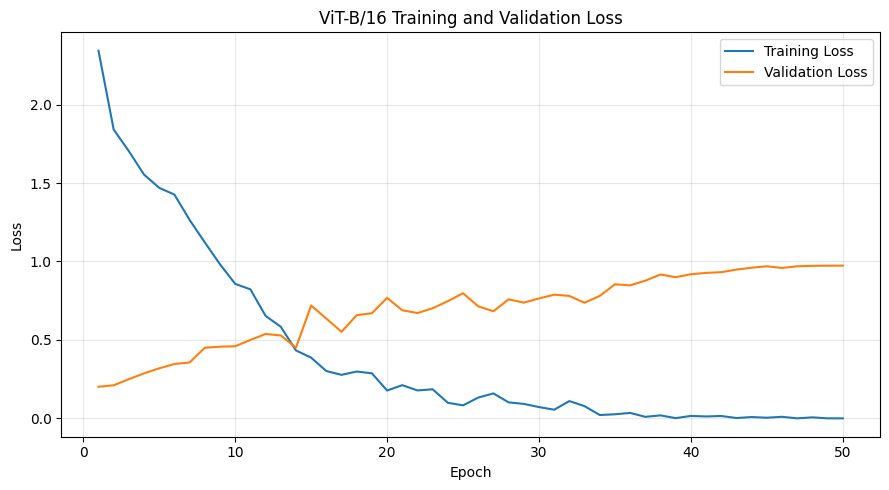

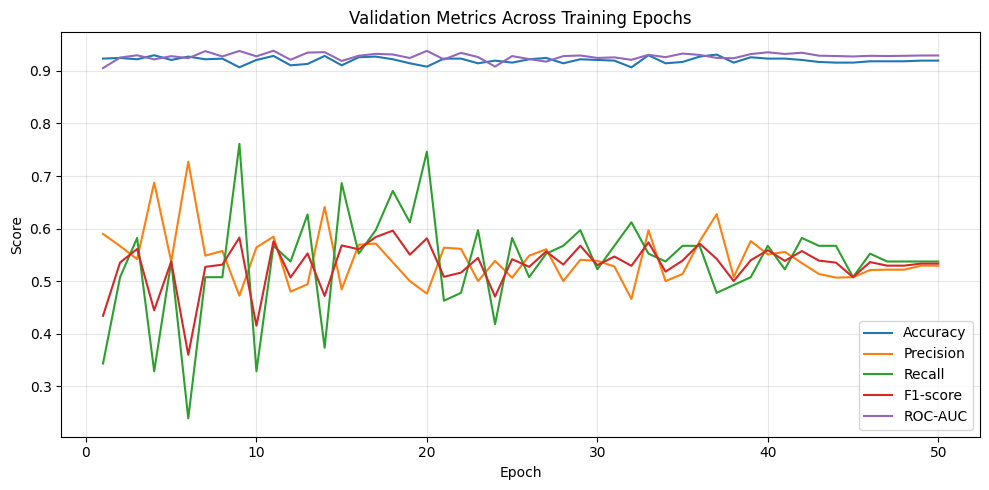

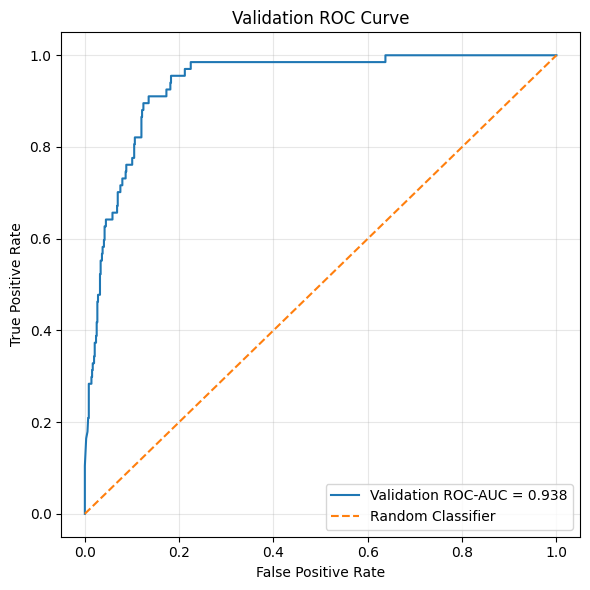

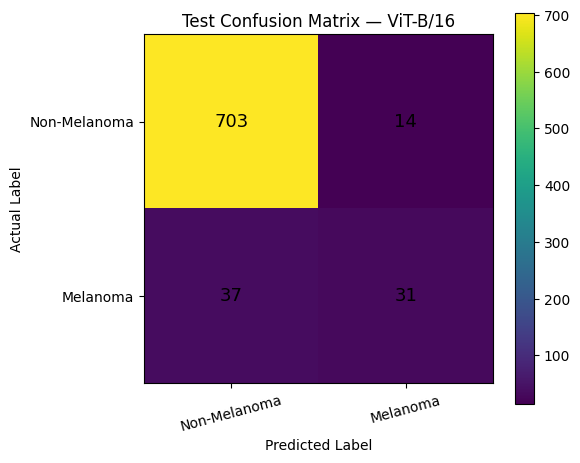

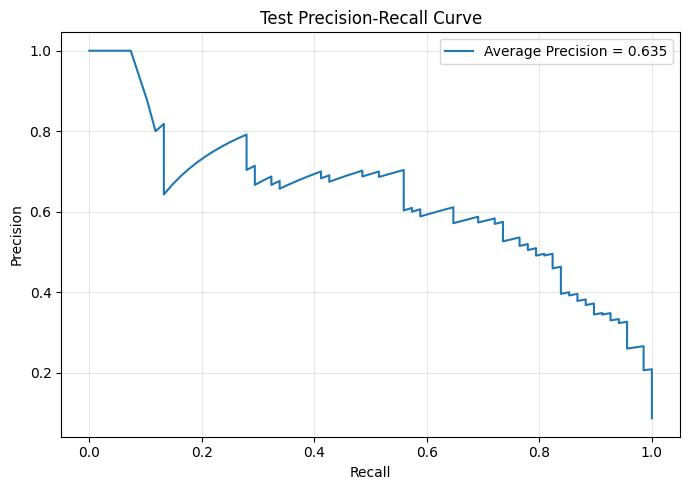

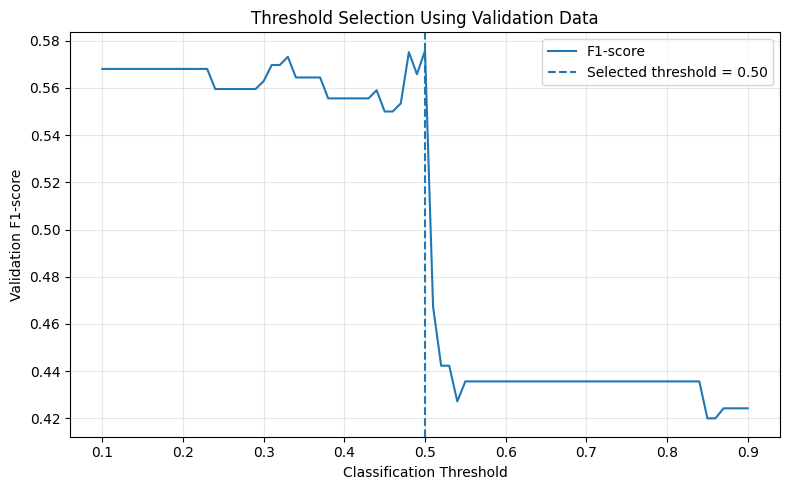

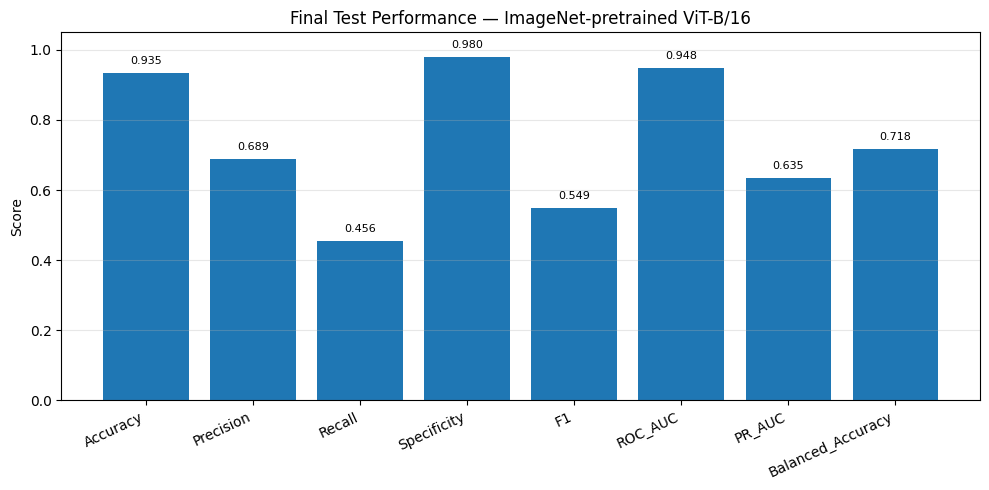


TRAINING AND EVALUATION COMPLETED
Best model: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/vit_models/best_imagenet_vit_b16.pth
Model with threshold: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/vit_models/best_imagenet_vit_b16_with_threshold.pth
Training history: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_training_history.csv
Threshold analysis: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_threshold_analysis.csv
Test predictions: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_test_results.csv
Test metrics: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_test_metrics.csv

All report graphs and CSV results are saved in:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports


In [ ]:
# ================================================================
# PROJECT: MELANOMA CLASSIFICATION USING VISION TRANSFORMER (ViT)
#
# METHODS USED:
# 1. Transfer Learning: ImageNet-pretrained ViT-B/16.
# 2. Fine-tuning: Train the pretrained transformer and classifier head.
# 3. Image Preprocessing: Resize/crop images to 224 x 224 and normalize.
# 4. Data Augmentation: Random crop, horizontal/vertical flip,
#    rotation, and brightness/contrast adjustment.
# 5. Class Imbalance Handling: Weighted Binary Cross-Entropy Loss.
# 6. Optimization: AdamW with separate learning rates for the
#    pretrained backbone and the classification head.
# 7. Learning Rate Scheduling: Warm-up followed by cosine decay.
# 8. Regularization: Weight decay, dropout in ViT, and gradient clipping.
# 9. Training: 50 epochs, with mixed precision when CUDA is available.
# 10. Model Selection: Save the model with the best validation ROC-AUC.
# 11. Lesion-Level Evaluation: Average predictions from both images
#     belonging to the same lesion.
# 12. Threshold Selection: Select the classification threshold using
#     validation F1-score, then evaluate once on the held-out test set.
# 13. Outputs: Training history, metrics CSVs, trained model, and graphs.
#
# LABELS:
# 0 = Non-Melanoma
# 1 = Melanoma
#
# NOTE:
# This is an educational research prototype, not a clinical diagnostic
# system. The original prepared train/validation/test split is preserved.
# ================================================================

import os
import math
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights

warnings.filterwarnings("ignore")

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
EPOCHS = 50
BATCH_SIZE = 8
WARMUP_EPOCHS = 3
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4
IMAGE_SIZE = 224

BASE_DIR = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data"
DATA_DIR = os.path.join(BASE_DIR, "MILK10k_Prepared")
REPORT_DIR = os.path.join(DATA_DIR, "reports")
MODEL_DIR = os.path.join(DATA_DIR, "vit_models")

TRAIN_CSV = os.path.join(DATA_DIR, "train_lesions.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation_lesions.csv")
TEST_CSV = os.path.join(DATA_DIR, "test_lesions.csv")

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print("=" * 65)
print("VISION TRANSFORMER WITH IMAGENET TRANSFER LEARNING")
print("=" * 65)
print("Device:", device)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Mixed precision:", USE_AMP)
print("Dataset directory:", DATA_DIR)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not os.path.isfile(csv_path):
        raise FileNotFoundError(f"CSV file not found: {csv_path}")

# -------------------- 2. LOAD AND VERIFY SPLITS --------------------

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

required_columns = {"lesion_id", "label"}

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    if not required_columns.issubset(df.columns):
        raise ValueError(f"{name} CSV must contain {required_columns}")

    df["lesion_id"] = df["lesion_id"].astype(str)
    df["label"] = df["label"].astype(int)

    if not set(df["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name} labels must be 0 or 1.")

train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

if train_ids & val_ids or train_ids & test_ids or val_ids & test_ids:
    raise ValueError("Lesion leakage detected: split IDs overlap.")

print("\nLESION-LEVEL DATA DISTRIBUTION")
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(df)} lesions | "
        f"Non-Melanoma: {(df['label'] == 0).sum()} | "
        f"Melanoma: {(df['label'] == 1).sum()}"
    )

# -------------------- 3. IMAGE TRANSFORMS --------------------

# ImageNet normalization is required when using ImageNet-pretrained weights.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.80, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# -------------------- 4. DATASET --------------------

class MelanomaDataset(Dataset):
    def __init__(self, dataframe, split_name, transform):
        self.transform = transform
        self.samples = []

        split_dir = os.path.join(DATA_DIR, split_name)

        if not os.path.isdir(split_dir):
            raise FileNotFoundError(f"Image folder not found: {split_dir}")

        for _, row in dataframe.iterrows():
            lesion_id = str(row["lesion_id"])
            label = int(row["label"])
            lesion_dir = os.path.join(split_dir, lesion_id)

            if not os.path.isdir(lesion_dir):
                raise FileNotFoundError(
                    f"Missing lesion folder: {lesion_dir}"
                )

            image_files = sorted([
                f for f in os.listdir(lesion_dir)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

            if len(image_files) != 2:
                raise ValueError(
                    f"Expected 2 images for {lesion_id}, "
                    f"but found {len(image_files)} in {lesion_dir}"
                )

            for image_file in image_files:
                image_path = os.path.join(lesion_dir, image_file)
                self.samples.append((image_path, label, lesion_id))

        print(
            f"{split_name}: {len(self.samples)} images from "
            f"{len(dataframe)} lesions"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label, lesion_id = self.samples[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32), lesion_id


train_dataset = MelanomaDataset(train_df, "train", train_transform)
val_dataset = MelanomaDataset(val_df, "validation", eval_transform)
test_dataset = MelanomaDataset(test_df, "test", eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=USE_AMP
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=USE_AMP
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=USE_AMP
)

# -------------------- 5. BUILD PRETRAINED ViT-B/16 --------------------

print("\nLoading ImageNet-pretrained ViT-B/16...")

# Downloads pretrained weights if they are not already cached.
weights = ViT_B_16_Weights.IMAGENET1K_V1
model = vit_b_16(weights=weights)

# Replace the original 1000-class ImageNet head with a binary classifier.
in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, 1)

model = model.to(device)

print("Model: Vision Transformer Base / Patch 16")
print("Pretrained weights: ImageNet-1K")
print("Output classes: 1 (binary logit)")
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# -------------------- 6. LOSS, OPTIMIZER AND SCHEDULER --------------------

train_labels = np.array([label for _, label, _ in train_dataset.samples])
negative_count = int(np.sum(train_labels == 0))
positive_count = int(np.sum(train_labels == 1))

if positive_count == 0:
    raise ValueError("No melanoma samples found in the training split.")

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
validation_criterion = nn.BCEWithLogitsLoss()

backbone_params = [
    p for name, p in model.named_parameters()
    if not name.startswith("heads.")
]

head_params = list(model.heads.parameters())

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": BACKBONE_LR},
        {"params": head_params, "lr": HEAD_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

def lr_lambda(epoch):
    if epoch < WARMUP_EPOCHS:
        return float(epoch + 1) / WARMUP_EPOCHS

    progress = (epoch - WARMUP_EPOCHS) / (EPOCHS - WARMUP_EPOCHS)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lr_lambda=lr_lambda
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("\nPositive-class weight:", round(negative_count / positive_count, 3))
print("Optimizer: AdamW")
print("Backbone learning rate:", BACKBONE_LR)
print("Classifier learning rate:", HEAD_LR)
print("Weight decay:", WEIGHT_DECAY)

# -------------------- 7. EVALUATION HELPER --------------------

def evaluate_model(loader):
    model.eval()

    total_loss = 0.0
    total_images = 0

    image_probabilities = []
    image_labels = []
    image_lesion_ids = []

    with torch.no_grad():
        for images, labels, lesion_ids in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).view(-1, 1)

            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits = model(images)
                loss = validation_criterion(logits, labels)

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_images += batch_size

            probabilities = torch.sigmoid(logits).squeeze(1).cpu().numpy()

            image_probabilities.extend(probabilities.tolist())
            image_labels.extend(labels.squeeze(1).cpu().numpy().tolist())
            image_lesion_ids.extend(list(lesion_ids))

    # Aggregate the two image probabilities into one lesion probability.
    result_df = pd.DataFrame({
        "lesion_id": image_lesion_ids,
        "label": image_labels,
        "probability": image_probabilities
    })

    label_counts = result_df.groupby("lesion_id")["label"].nunique()
    if (label_counts != 1).any():
        raise ValueError("Inconsistent labels found for a lesion.")

    image_counts = result_df.groupby("lesion_id").size()
    if (image_counts != 2).any():
        raise ValueError("Every evaluated lesion must have exactly 2 images.")

    lesion_df = result_df.groupby("lesion_id", as_index=False).agg(
        label=("label", "first"),
        probability=("probability", "mean")
    )

    val_loss = total_loss / max(total_images, 1)

    return val_loss, lesion_df


def calculate_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "Specificity": specificity,
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# -------------------- 8. TRAIN FOR 50 EPOCHS --------------------

history = []
best_val_auc = -1.0
best_epoch = 0
best_model_path = os.path.join(MODEL_DIR, "best_imagenet_vit_b16.pth")

print("\nStarting training...")
print("=" * 100)

for epoch in range(EPOCHS):
    model.train()

    running_loss = 0.0
    total_train_images = 0

    for images, labels, _ in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).view(-1, 1)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()

        # Prevent excessively large gradients.
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        running_loss += loss.item() * batch_size
        total_train_images += batch_size

    train_loss = running_loss / max(total_train_images, 1)

    val_loss, val_lesions = evaluate_model(val_loader)

    y_val = val_lesions["label"].to_numpy(dtype=int)
    p_val = val_lesions["probability"].to_numpy(dtype=float)

    val_metrics_05 = calculate_metrics(y_val, p_val, threshold=0.5)
    val_auc = val_metrics_05["ROC_AUC"]
    val_pr_auc = val_metrics_05["PR_AUC"]

    current_backbone_lr = optimizer.param_groups[0]["lr"]
    current_head_lr = optimizer.param_groups[1]["lr"]

    history.append({
        "Epoch": epoch + 1,
        "Train_Loss": train_loss,
        "Validation_Loss": val_loss,
        "Validation_Accuracy": val_metrics_05["Accuracy"],
        "Validation_Precision": val_metrics_05["Precision"],
        "Validation_Recall": val_metrics_05["Recall"],
        "Validation_F1": val_metrics_05["F1"],
        "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_pr_auc,
        "Backbone_LR": current_backbone_lr,
        "Head_LR": current_head_lr
    })

    # Save the best model based on validation ROC-AUC.
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_epoch = epoch + 1

        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_metrics_05['Accuracy']:.4f} | "
        f"Val Recall: {val_metrics_05['Recall']:.4f} | "
        f"Val F1: {val_metrics_05['F1']:.4f} | "
        f"Val ROC-AUC: {val_auc:.4f} | "
        f"Val PR-AUC: {val_pr_auc:.4f}"
    )

    scheduler.step()

    if device.type == "cuda":
        torch.cuda.empty_cache()

print("=" * 100)
print("Training completed.")
print("Best epoch:", best_epoch)
print("Best validation ROC-AUC:", round(best_val_auc, 4))
print("Best model saved to:", best_model_path)

# -------------------- 9. SAVE TRAINING HISTORY --------------------

history_df = pd.DataFrame(history)

history_path = os.path.join(
    REPORT_DIR, "imagenet_vit_training_history.csv"
)
history_df.to_csv(history_path, index=False)

# -------------------- 10. LOAD BEST MODEL --------------------

model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

# -------------------- 11. SELECT THRESHOLD USING VALIDATION ONLY --------------------

_, val_lesions = evaluate_model(val_loader)

y_val = val_lesions["label"].to_numpy(dtype=int)
p_val = val_lesions["probability"].to_numpy(dtype=float)

threshold_rows = []

for threshold in np.arange(0.10, 0.901, 0.01):
    metrics = calculate_metrics(y_val, p_val, threshold)
    threshold_rows.append(metrics)

threshold_df = pd.DataFrame(threshold_rows)

# Maximize validation F1. If tied, prefer the threshold closest to 0.50.
best_f1 = threshold_df["F1"].max()
tied = threshold_df[
    np.isclose(threshold_df["F1"], best_f1)
].copy()

tied["Distance_From_050"] = abs(tied["Threshold"] - 0.50)
best_threshold = float(
    tied.sort_values("Distance_From_050").iloc[0]["Threshold"]
)

threshold_path = os.path.join(
    REPORT_DIR, "imagenet_vit_threshold_analysis.csv"
)
threshold_df.to_csv(threshold_path, index=False)

print("\nVALIDATION-BASED THRESHOLD SELECTION")
print("Selected threshold:", round(best_threshold, 3))
print("Validation F1 at selected threshold:", round(best_f1, 4))

# -------------------- 12. FINAL TEST EVALUATION --------------------

# The test set is evaluated after model and threshold selection.
_, test_lesions = evaluate_model(test_loader)

y_test = test_lesions["label"].to_numpy(dtype=int)
p_test = test_lesions["probability"].to_numpy(dtype=float)

test_metrics = calculate_metrics(
    y_test, p_test, threshold=best_threshold
)

test_result_df = test_lesions.copy()
test_result_df["prediction"] = (
    test_result_df["probability"] >= best_threshold
).astype(int)

test_result_df["prediction_name"] = test_result_df["prediction"].map({
    0: "Non-Melanoma",
    1: "Melanoma"
})

test_result_df["actual_name"] = test_result_df["label"].map({
    0: "Non-Melanoma",
    1: "Melanoma"
})

test_result_df.to_csv(
    os.path.join(REPORT_DIR, "imagenet_vit_test_results.csv"),
    index=False
)

metrics_df = pd.DataFrame([test_metrics])
metrics_df.to_csv(
    os.path.join(REPORT_DIR, "imagenet_vit_test_metrics.csv"),
    index=False
)

# Save the selected threshold with the model for future inference.
torch.save({
    "model_state_dict": model.state_dict(),
    "best_epoch": best_epoch,
    "validation_roc_auc": best_val_auc,
    "classification_threshold": best_threshold,
    "image_size": IMAGE_SIZE,
    "model_name": "ViT-B/16 ImageNet pretrained"
}, os.path.join(MODEL_DIR, "best_imagenet_vit_b16_with_threshold.pth"))

# -------------------- 13. PRINT TEST RESULTS --------------------

print("\n" + "=" * 65)
print("FINAL TEST RESULTS — LESION LEVEL")
print("=" * 65)

print("Best epoch:", best_epoch)
print(f"Validation ROC-AUC: {best_val_auc:.4f}")
print(f"Classification threshold: {best_threshold:.2f}")
print(f"Test lesions: {len(test_lesions)}")
print(f"Accuracy:           {test_metrics['Accuracy']:.4f}")
print(f"Precision:          {test_metrics['Precision']:.4f}")
print(f"Recall/Sensitivity: {test_metrics['Recall']:.4f}")
print(f"Specificity:        {test_metrics['Specificity']:.4f}")
print(f"F1-score:           {test_metrics['F1']:.4f}")
print(f"ROC-AUC:            {test_metrics['ROC_AUC']:.4f}")
print(f"PR-AUC:             {test_metrics['PR_AUC']:.4f}")
print(f"Balanced Accuracy:  {test_metrics['Balanced_Accuracy']:.4f}")

print("\nCONFUSION MATRIX")
print("TN:", test_metrics["TN"], "| FP:", test_metrics["FP"])
print("FN:", test_metrics["FN"], "| TP:", test_metrics["TP"])

print("\nAll metrics are proportions. Multiply by 100 for percentages.")

# -------------------- 14. GRAPH 1: TRAINING AND VALIDATION LOSS --------------------

plt.figure(figsize=(9, 5))
plt.plot(history_df["Epoch"], history_df["Train_Loss"], label="Training Loss")
plt.plot(history_df["Epoch"], history_df["Validation_Loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ViT-B/16 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_loss_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 15. GRAPH 2: VALIDATION METRICS --------------------

plt.figure(figsize=(10, 5))
plt.plot(history_df["Epoch"], history_df["Validation_Accuracy"], label="Accuracy")
plt.plot(history_df["Epoch"], history_df["Validation_Precision"], label="Precision")
plt.plot(history_df["Epoch"], history_df["Validation_Recall"], label="Recall")
plt.plot(history_df["Epoch"], history_df["Validation_F1"], label="F1-score")
plt.plot(history_df["Epoch"], history_df["Validation_ROC_AUC"], label="ROC-AUC")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Metrics Across Training Epochs")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_validation_metrics.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 16. GRAPH 3: VALIDATION ROC CURVE --------------------

fpr_val, tpr_val, _ = roc_curve(y_val, p_val)

plt.figure(figsize=(6, 6))
plt.plot(
    fpr_val, tpr_val,
    label=f"Validation ROC-AUC = {roc_auc_score(y_val, p_val):.3f}"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_validation_roc.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 17. GRAPH 4: TEST CONFUSION MATRIX --------------------

cm = confusion_matrix(
    y_test,
    test_result_df["prediction"].to_numpy(),
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Test Confusion Matrix — ViT-B/16")
fig.colorbar(im, ax=ax)

class_names = ["Non-Melanoma", "Melanoma"]
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names, rotation=15)
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center", fontsize=13
        )

plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_test_confusion_matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 18. GRAPH 5: TEST PRECISION-RECALL CURVE --------------------

precision_values, recall_values, _ = precision_recall_curve(y_test, p_test)
pr_auc_test = average_precision_score(y_test, p_test)

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values, precision_values,
    label=f"Average Precision = {pr_auc_test:.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_test_precision_recall.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 19. GRAPH 6: VALIDATION THRESHOLD ANALYSIS --------------------

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["Threshold"], threshold_df["F1"], label="F1-score")
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)
plt.xlabel("Classification Threshold")
plt.ylabel("Validation F1-score")
plt.title("Threshold Selection Using Validation Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_threshold_f1.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 20. GRAPH 7: FINAL TEST METRICS --------------------

metric_names = [
    "Accuracy", "Precision", "Recall",
    "Specificity", "F1", "ROC_AUC", "PR_AUC",
    "Balanced_Accuracy"
]

metric_values = [test_metrics[name] for name in metric_names]

plt.figure(figsize=(10, 5))
bars = plt.bar(metric_names, metric_values)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Final Test Performance — ImageNet-pretrained ViT-B/16")
plt.xticks(rotation=25, ha="right")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center", va="bottom", fontsize=8
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "imagenet_vit_test_metrics.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# -------------------- 21. FINAL OUTPUT LOCATIONS --------------------

print("\n" + "=" * 65)
print("TRAINING AND EVALUATION COMPLETED")
print("=" * 65)
print("Best model:", best_model_path)
print("Model with threshold:", os.path.join(
    MODEL_DIR, "best_imagenet_vit_b16_with_threshold.pth"
))
print("Training history:", history_path)
print("Threshold analysis:", threshold_path)
print("Test predictions:", os.path.join(
    REPORT_DIR, "imagenet_vit_test_results.csv"
))
print("Test metrics:", os.path.join(
    REPORT_DIR, "imagenet_vit_test_metrics.csv"
))
print("\nAll report graphs and CSV results are saved in:")
print(REPORT_DIR)

In [ ]:

import os

ROOT = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

target = "vit_test_metrics_threshold_048.csv"

print("Searching for:", target)

for root, dirs, files in os.walk(ROOT):
    if target in files:
        print("FOUND:", os.path.join(root, target))


Searching for: vit_test_metrics_threshold_048.csv
FOUND: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/vit_test_metrics_threshold_048.csv


In [ ]:
import os

ROOT = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

print("Searching for validation prediction CSV files...\n")

for root, dirs, files in os.walk(ROOT):
    for file in files:
        name = file.lower()
        if file.endswith(".csv") and (
            "val" in name or "validation" in name
        ):
            print(os.path.join(root, file))

Searching for validation prediction CSV files...

/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/validation_lesions.csv
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/splits/validation_processed.csv
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/splits/validation_failed.csv
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/validation_threshold_analysis.csv


In [ ]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

for root, dirs, files in os.walk(ROOT):
    for file in files:
        if file.lower() == "imagenet_vit_threshold_analysis.csv":
            path = os.path.join(root, file)
            print("Found:", path)

            threshold_df = pd.read_csv(path)

            print("\nColumns:", threshold_df.columns.tolist())
            print("\nThreshold analysis:\n")
            print(threshold_df.to_string(index=False))

Found: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_threshold_analysis.csv

Columns: ['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'PR_AUC', 'Balanced_Accuracy', 'TN', 'FP', 'FN', 'TP']

Threshold analysis:

 Threshold  Accuracy  Precision   Recall  Specificity       F1  ROC_AUC   PR_AUC  Balanced_Accuracy  TN  FP  FN  TP
      0.10  0.906888   0.470588 0.716418     0.924686 0.568047 0.938487 0.603548           0.820552 663  54  19  48
      0.11  0.906888   0.470588 0.716418     0.924686 0.568047 0.938487 0.603548           0.820552 663  54  19  48
      0.12  0.906888   0.470588 0.716418     0.924686 0.568047 0.938487 0.603548           0.820552 663  54  19  48
      0.13  0.906888   0.470588 0.716418     0.924686 0.568047 0.938487 0.603548           0.820552 663  54  19  48
      0.14  0.906888   0.470588 0.716418     0.924686 0.568047 0.938487 0.603548           0.820552 663  54  19  48
      0.15  

In [ ]:
import pandas as pd
import os

CSV_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/imagenet_vit_threshold_analysis.csv"

threshold_df = pd.read_csv(CSV_PATH)

print("Columns:", threshold_df.columns.tolist())
print("Number of rows:", len(threshold_df))

if "Balanced_Accuracy" not in threshold_df.columns:
    threshold_df["Balanced_Accuracy"] = (
        threshold_df["Recall"] + threshold_df["Specificity"]
    ) / 2

cols = [
    "Threshold",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Balanced_Accuracy"
]

print("\nBEST THRESHOLDS BY VALIDATION F1-SCORE:")
print(
    threshold_df.sort_values("F1", ascending=False)[cols]
    .head(10)
    .round(4)
    .to_string(index=False)
)

print("\nTHRESHOLDS WITH VALIDATION RECALL >= 0.70:")
candidates = threshold_df[threshold_df["Recall"] >= 0.70]

if not candidates.empty:
    print(
        candidates.sort_values("F1", ascending=False)[cols]
        .head(10)
        .round(4)
        .to_string(index=False)
    )
else:
    print("No tested threshold achieved recall >= 0.70.")

Columns: ['Threshold', 'Accuracy', 'Precision', 'Recall', 'Specificity', 'F1', 'ROC_AUC', 'PR_AUC', 'Balanced_Accuracy', 'TN', 'FP', 'FN', 'TP']
Number of rows: 81

BEST THRESHOLDS BY VALIDATION F1-SCORE:
 Threshold  Precision  Recall  Specificity     F1  Balanced_Accuracy
      0.50     0.5846  0.5672       0.9623 0.5758             0.7648
      0.48     0.5116  0.6567       0.9414 0.5752             0.7991
      0.33     0.4845  0.7015       0.9303 0.5732             0.8159
      0.31     0.4796  0.7015       0.9289 0.5697             0.8152
      0.32     0.4796  0.7015       0.9289 0.5697             0.8152
      0.11     0.4706  0.7164       0.9247 0.5680             0.8206
      0.12     0.4706  0.7164       0.9247 0.5680             0.8206
      0.13     0.4706  0.7164       0.9247 0.5680             0.8206
      0.18     0.4706  0.7164       0.9247 0.5680             0.8206
      0.19     0.4706  0.7164       0.9247 0.5680             0.8206

THRESHOLDS WITH VALIDATION RECALL >

In [ ]:

# Evaluate the validation-selected threshold on the held-out test set

selected_threshold = 0.48

y_test = test_lesions["label"].to_numpy(dtype=int)
p_test = test_lesions["probability"].to_numpy(dtype=float)

test_metrics_048 = calculate_metrics(
    y_test, p_test, threshold=selected_threshold
)

print("=" * 55)
print("TEST RESULTS — SELECTED THRESHOLD 0.48")
print("=" * 55)
print("Threshold:", selected_threshold)

for metric in [
    "Accuracy", "Precision", "Recall", "Specificity",
    "F1", "ROC_AUC", "PR_AUC", "Balanced_Accuracy"
]:
    print(f"{metric}: {test_metrics_048[metric]:.4f}")

print("\nConfusion Matrix Counts")
print("TN:", test_metrics_048["TN"])
print("FP:", test_metrics_048["FP"])
print("FN:", test_metrics_048["FN"])
print("TP:", test_metrics_048["TP"])

# Save separately to preserve the original baseline results
import pandas as pd
import os

pd.DataFrame([test_metrics_048]).to_csv(
    os.path.join(REPORT_DIR, "vit_test_metrics_threshold_048.csv"),
    index=False
)

print("\nResults saved separately.")


TEST RESULTS — SELECTED THRESHOLD 0.48
Threshold: 0.48
Accuracy: 0.9299
Precision: 0.6000
Recall: 0.5735
Specificity: 0.9637
F1: 0.5865
ROC_AUC: 0.9479
PR_AUC: 0.6349
Balanced_Accuracy: 0.7686

Confusion Matrix Counts
TN: 691
FP: 26
FN: 29
TP: 39

Results saved separately.


Saved test metrics:
 Threshold  Accuracy  Precision   Recall  Specificity       F1  ROC_AUC  PR_AUC  Balanced_Accuracy  TN  FP  FN  TP
      0.48  0.929936        0.6 0.573529     0.963738 0.586466 0.947894 0.63488           0.768634 691  26  29  39

Confusion Matrix — ViT-B/16 Transfer Learning
Threshold: 0.48
[[691  26]
 [ 29  39]]


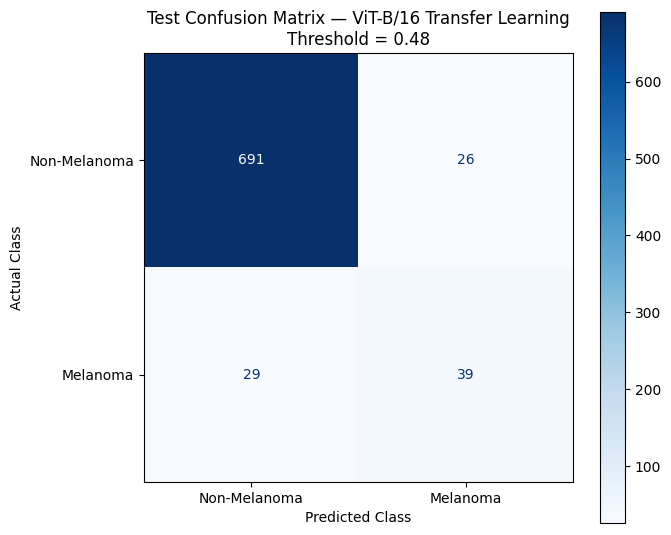


Confusion matrix saved successfully:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports/vit_transfer_learning_confusion_matrix_048.png


In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

REPORT_DIR = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/reports"

metrics_path = os.path.join(
    REPORT_DIR, "vit_test_metrics_threshold_048.csv"
)
metrics_df = pd.read_csv(metrics_path)

print("Saved test metrics:")
print(metrics_df.to_string(index=False))

tn = int(metrics_df.loc[0, "TN"])
fp = int(metrics_df.loc[0, "FP"])
fn = int(metrics_df.loc[0, "FN"])
tp = int(metrics_df.loc[0, "TP"])

cm = np.array([
    [tn, fp],
    [fn, tp]
])

print("\nConfusion Matrix — ViT-B/16 Transfer Learning")
print("Threshold: 0.48")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Melanoma", "Melanoma"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=True
)

ax.set_title(
    "Test Confusion Matrix — ViT-B/16 Transfer Learning\nThreshold = 0.48"
)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()

output_path = os.path.join(
    REPORT_DIR, "vit_transfer_learning_confusion_matrix_048.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nConfusion matrix saved successfully:")
print(output_path)

